# IMF Country Report → Text-to-Dashboard LLM Pipeline
**Module:** Data Analysis with AI (7PAM2032) — Assignment 1: LLM Coding Case Study

**Document analysed:** *Switzerland: 2026 Article IV Consultation — Press Release; and Staff Report* (IMF Country Report No. 26/233, staff report dated 4 August 2026; Board conclusion 25 August 2026, lapse-of-time basis).

This notebook implements an end-to-end pipeline:

| Stage | What happens | Brief task |
|---|---|---|
| 1 | PDF ingestion → cleaning (headers/footers, chart residue, pypdf decimal-split repair) → token-aware overlapping chunks | Task 1 |
| 2 | Executive summary + per-section summaries (< 100 words) with an **LLM-as-a-Judge** evaluator | Task 1 |
| 3 | Thematic distribution (LLM multi-label vs keyword baseline), strengths / vulnerabilities | Task 2 |
| 4 | Schema-constrained JSON indicator extraction with evidence, validation, judge audit, human ground truth and fallback capture | Task 2 |
| 5 | Temporal trend extraction from statistical tables (LLM) cross-checked by a deterministic table parser | Task 2 |
| 6 | Local RAG: `sentence-transformers` (DistilBERT) embeddings + FAISS `IndexFlatL2`, grounded Q&A, RAG-triad judging, closed-book baseline | Task 3 |
| 7 | Extension: strict `system_instruction` + native schema **vs** generic user prompt | Extra credit |
| 8 | Tidy data with `pd.melt` and a multi-plot dashboard (300 dpi) | Task 4 |

### How to run
1. **Runtime → Run all.** No GPU is needed.
2. **With an API key (live mode):** add a Colab secret named `GEMINI_API_KEY` (key icon in the left sidebar) and enable notebook access. Every LLM response is written to `cache/llm_cache.json`.
3. **Without an API key (replay mode):** the notebook replays the committed `cache/llm_cache.json`, so every number and figure is reproduced exactly without network calls to the LLM.

The PDF is downloaded from the IMF website (it is not redistributed in the repository).

In [1]:
# --- Install dependencies (Colab already ships pandas, numpy, matplotlib, seaborn, requests) ---
# Optional: pin pypdf to the version used in the live run (see `!pip show pypdf`), e.g. "pypdf==6.1.3",
# so a marker's session extracts identical text. Replay also tolerates small differences (tag-based fallback).
!pip -q install google-genai sentence-transformers faiss-cpu pypdf jsonschema

# --- Fresh-session setup (e.g. a marker opening this notebook from GitHub) ---
# Opening a notebook from GitHub in Colab does NOT bring the repository files with it, so the committed
# cache/, outputs/ and figures/ folders are cloned here and the working directory is moved into the clone.
import os
REPO_URL = "https://github.com/<YOUR_GITHUB_USER>/<YOUR_REPO>.git"   # <-- set to your public repository
if not os.path.exists("cache/llm_cache.json") and "<YOUR_GITHUB_USER>" not in REPO_URL:
    if not os.path.exists("/content/repo"):
        !git clone -q {REPO_URL} /content/repo
    %cd /content/repo
print("Working directory:", os.getcwd(), "| committed LLM cache present:", os.path.exists("cache/llm_cache.json"))

## 0. Configuration
All tunable choices live in this cell so the pipeline can be re-pointed at another IMF report by editing
`COUNTRY`, `PDF_URL`, `SECTION_MARKERS`, `TABLE_PAGE_PATTERNS` and `GROUND_TRUTH`.

In [2]:
import os, re, json, time, hashlib, difflib, sys, textwrap, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import jsonschema
import requests
from pypdf import PdfReader

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------- Document ----------------
COUNTRY = "Switzerland"
REPORT_LABEL = "IMF Country Report No. 26/233 — Switzerland 2026 Article IV"
REPORT_YEAR = 2026                      # reference year for forecast-type indicators
PDF_PATH = Path("data/imf_report.pdf")
PDF_URL = "https://www.imf.org/-/media/files/publications/cr/2026/english/1cheea2026001.pdf"

# ---------------- Folders ----------------
OUT_DIR, FIG_DIR, CACHE_DIR = Path("outputs"), Path("figures"), Path("cache")
for d in (OUT_DIR, FIG_DIR, CACHE_DIR, PDF_PATH.parent):
    d.mkdir(parents=True, exist_ok=True)
CACHE_PATH = CACHE_DIR / "llm_cache.json"
RUN_CONFIG_PATH = OUT_DIR / "run_config.json"

# ---------------- LLMs (Google Gemini) ----------------
# Preference lists: the first model available to your API key is used. The judge must differ from the
# generator to reduce self-enhancement bias (Zheng et al., 2023). Override with explicit names if needed.
GEN_MODEL_PREFS = ["gemini-3.5-flash", "gemini-3-flash", "gemini-2.5-flash"]
JUDGE_MODEL_PREFS = ["gemini-3.8-flash", "gemini-3-flash", "gemini-2.5-flash", "gemini-3.5-flash-lite"]  # Pro models usually need a paid key
GEN_MODEL_OVERRIDE = None               # e.g. "gemini-3.5-flash"
JUDGE_MODEL_OVERRIDE = None             # e.g. "gemini-3.8-flash"
TEMPERATURE = 0.0                       # deterministic decoding for extraction & judging (Lecture 2)
SEED = 42
MIN_SECONDS_BETWEEN_CALLS = 4.0         # free-tier friendly pacing
MAX_API_RETRIES = 6

# ---------------- Chunking & retrieval ----------------
EMBED_MODEL_NAME = "sentence-transformers/multi-qa-distilbert-cos-v1"   # DistilBERT, tuned for QA retrieval
CHUNK_TOKENS = 350                      # brief: 300–500 tokens; kept well inside the 512-token encoder limit
OVERLAP_TOKENS = 50                     # brief: 50-token overlap
TOP_K = 4                               # Lecture 3: k in {3,4,5}
EXCLUDE_CHART_PAGES = True              # chart pages only contain axis labels / tick values

# ---------------- Themes (brief, Task 2) ----------------
THEMES = ["Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate",
          "Banking Capital & Liquidity", "Sovereign Debt", "Labor Market Dynamics", "Systemic Financial Risk"]
THEME_BATCH = 10                        # chunks per classification call

# ---------------- Extension ----------------
RUN_EXTENSION = True                    # strict system_instruction vs generic user prompt
EXT_REPEATS = 3                         # repeated calls per variant (latency / compliance statistics)
RUN_CLOSED_BOOK_BASELINE = True         # RAG vs no-retrieval comparison

### Human-verified ground truth
Values below were **checked manually against the PDF** (page numbers are PDF pages). They are used only for
*evaluating* the pipeline (accuracy, judge–human agreement) — never as model input.
Reference-year rule: forecast indicators use the staff projection for `REPORT_YEAR`; rates/ratios use the latest actual value.

In [3]:
GROUND_TRUTH = {
    "country_name": {"value": "Switzerland", "page": 2, "note": ""},
    "gdp_growth_forecast_pct": {"value": 0.8, "page": 14, "note": "2026 staff projection adj. for sporting events (narrative ¶9). Non-adjusted = 1.1 (p.14; Table 1 p.40)."},
    "headline_inflation_rate_pct": {"value": 0.6, "page": 14, "note": "2026 average CPI projection (¶9; Table 1). Latest actual June 2026 y/y = 0.5 (p.10); core = 0.3; 2025 avg = 0.2."},
    "central_bank_policy_rate_pct": {"value": 0.0, "page": 12, "note": "SNB policy rate at zero since June 2025 (unchanged)."},
    "non_performing_loan_ratio": {"value": 0.8, "page": 45, "note": "Table 6, 2025, NPL % of gross loans. Only in the table, not in prose. NPL net of provisions % Tier 1 = 3.6 (different metric)."},
    "unemployment_rate_pct": {"value": 3.0, "page": 11, "note": "Latest actual (2026, ¶3). Table 1: 2025 = 2.8; 2026 projection = 3.1."},
    "tier_1_capital_ratio": {"value": 20.2, "page": 45, "note": "Table 6, 2025, Tier 1 % RWA (text p.12: 'above 20 percent'). Tier 1 % assets = 7.6 is the leverage ratio."},
}

### Section map and table locations
Sections are found by searching for their headings **in document order** (so the table of contents is skipped).
Entries flagged `False` delimit a region but are not summarised.

In [4]:
SECTION_MARKERS = [
    ("Press release & Executive Board assessment", r"IMF Executive Board Concludes", True),
    ("Press-release indicator table", r"Table 1\.\s*Switzerland: Selected Economic Indicators", False),
    ("Key issues", r"KEY ISSUES", True),
    ("Front matter & contents", r"Approved By", False),
    ("Context", r"CONTEXT: STABILITY AMID GLOBAL VOLATILITY(?![^\n]*_{3})", True),
    ("Economic developments since 2025", r"ECONOMIC DEVELOPMENTS SINCE 2025 ARTICLE IV(?![^\n]*_{3})", True),
    ("Outlook and risks", r"OUTLOOK AND RISKS: STAYING THE COURSE(?![^\n]*_{3})", True),
    ("Fiscal policy", r"Fiscal Policy: Managing Rising Expenditure", True),
    ("Monetary policy", r"Monetary Policy: Managing Increasingly Frequent", True),
    ("Financial sector", r"Financial Sector: Enhancing Systemic", True),
    ("Structural policies", r"Structural Policies: Enhancing Productivity", True),
    ("Staff appraisal", r"STAFF APPRAISAL(?![^\n]*_{3})", True),
    ("Statistical tables", r"Table 1\.\s*Switzerland: Selected Economic Indicators", False),
    ("Annex I: Banking sector concentration", r"Annex I\.\s*Banking Sector Concentration", True),
    ("Annex II: External sector assessment", r"Annex II\.\s*External Sector Assessment", True),
    ("Annex III: Competitiveness and resilience", r"Annex III\.\s*Competitiveness and Resilience", True),
    ("Annex IV: Risk assessment matrix", r"Annex IV\.\s*Risk Assessment Matrix", True),
    ("Annex V: Scenario analysis (QIPF model)", r"Annex V\.\s*Scenario Analysis", True),
    ("Annex VI: Long-term fiscal pressures", r"Annex VI\.\s*Long-Term Fiscal Pressures", True),
    ("Annex VII: Debt sustainability analysis", r"Annex VII\.\s*Debt Sustainability Analysis", True),
    ("Annex VIII: Safe-haven flows", r"Annex VIII\.\s*Safe-Haven Flows", True),
    ("Annex IX: Effects of low inflation", r"Annex IX\.\s*Effects of Low Inflation", True),
    ("Annex X: Implementation of 2025 FSAP recommendations", r"Annex X\.\s*Implementation of Key", True),
    ("Annex XI: Previous Article IV recommendations", r"Annex XI\.\s*Status of Previous", True),
    ("Annex XII: Transnational aspects of corruption", r"Annex XII\.\s*Transnational Aspects", True),
    ("Data issues & informational annex", r"Annex XIII\.\s*Data Issues", False),
]
# Narrative chapters used for strengths / vulnerabilities (must match titles above)
NARRATIVE_TITLES = ["Key issues", "Context", "Economic developments since 2025", "Outlook and risks", "Fiscal policy",
                    "Monetary policy", "Financial sector", "Structural policies", "Staff appraisal",
                    "Annex IV: Risk assessment matrix"]
# Statistical tables used for trend extraction (the matching page with the most machine-readable rows is used)
TABLE_PAGE_PATTERNS = {
    "Table 1 (Selected Economic Indicators)": r"Table 1\.\s*Switzerland: Selected Economic Indicators",
    "Table 6 (Bank Soundness Indicators)": r"Table 6\.\s*Switzerland: Bank Soundness Indicators",
}
# Series the trend extractor must return (exact row labels); the LLM may add further series it identifies.
TREND_TARGETS = [
    "Real GDP (adj. for sporting events)", "Consumer price index (period average)", "Unemployment rate (in percent)",
    "3-month Treasury bill interest rate (%)", "Yield on government bonds (7-year)", "Domestic credit, non-financial", "Gross debt",
    "Current account balance", "Regulatory Tier I capital as percent of risk-weighted assets",
    "Non-performing loans as percent of gross loans", "Liquidity Coverage Ratio",
]
# Series shown in the inflation-vs-rates dashboard panel: row label -> legend label
TREND_PLOT_SERIES = {"Consumer price index (period average)": "CPI inflation (avg, %)",
                     "3-month Treasury bill interest rate (%)": "3-month T-bill rate (%)",
                     "Yield on government bonds (7-year)": "7-year govt bond yield (%)",
                     "Real GDP (adj. for sporting events)": "Real GDP growth, adj. (%)"}
CREDIT_SERIES, NPL_SERIES = "Domestic credit, non-financial", "Non-performing loans as percent of gross loans"

# RAG test questions. Q2 is deliberately UNANSWERABLE from this document: the FSAP stress-test design is published
# separately (FSAP Technical Note on Systemic Risk Analysis and Stress Testing, IMF Country Report No. 25/311).
RAG_QUERIES = [
    {"id": "Q1", "answerable": True,
     "question": "What does the IMF recommend regarding capital buffers and macroprudential tools for residential real estate risks?"},
    {"id": "Q2", "answerable": False,
     "question": "What stress test scenario assumptions (e.g. GDP shock size, interest-rate path) were used in the FSAP bank stress tests?"},
    {"id": "Q3", "answerable": True,
     "question": "How does the SNB define price stability, and what inflation path do staff project for 2026 and 2027?"},
    {"id": "Q4", "answerable": True,
     "question": "What US tariff rate on Swiss goods does the baseline assume, and what is the effective tariff rate?"},
    {"id": "Q5", "answerable": True,
     "question": "By how much would the TBTF proposal on foreign subsidiaries raise UBS's CET1 capital requirements?"},
]

## 1. LLM client, response cache and robust JSON calling
* **Cache:** every call is keyed by a SHA-256 hash of (model, system prompt, user prompt, schema, temperature),
  so re-running is free and the marker can replay results without an API key.
* **Retries:** exponential back-off on rate limits / server errors.
* **Validation loop:** JSON outputs are parsed and validated with `jsonschema`; on failure the validator error is
  fed back to the model (self-repair loop, Lecture 2: "strict response schema validators with automated retry loops").

In [5]:
IN_COLAB = "google.colab" in sys.modules


def get_api_key():
    """Return a Gemini API key from Colab secrets or environment variables, or None (replay mode)."""
    if IN_COLAB:
        try:
            from google.colab import userdata
            key = userdata.get("GEMINI_API_KEY")
            if key:
                return key
        except Exception:
            pass
    return os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")


def load_cache():
    if CACHE_PATH.exists():
        return json.loads(CACHE_PATH.read_text(encoding="utf-8"))
    return {}


def save_cache():
    CACHE_PATH.write_text(json.dumps(LLM_CACHE, ensure_ascii=False, indent=1), encoding="utf-8")


LLM_CACHE = load_cache()
API_KEY = get_api_key()
CLIENT, types = None, None
if API_KEY:
    from google import genai
    from google.genai import types
    CLIENT = genai.Client(api_key=API_KEY)
MODE = "live" if CLIENT else "replay"
print(f"Mode: {MODE} | cached responses available: {len(LLM_CACHE)}")


def pick_model(prefs, override=None, avoid=None):
    """Choose the first preferred model that the API key can access."""
    if override:
        return override
    available = []
    for m in CLIENT.models.list():
        name = m.name.split("/")[-1]
        actions = getattr(m, "supported_actions", None) or ["generateContent"]
        if "generateContent" in actions:
            available.append(name)
    for p in prefs:
        if p in available and p != avoid:
            return p
    # fallback: plain text models such as 'gemini-2.5-flash' (skip image / tts / audio / live variants), newest first
    plain = [a for a in available if re.fullmatch(r"gemini-\d+(?:\.\d+)?-(?:flash|flash-lite|pro)", a) and a != avoid]
    plain.sort(key=lambda a: (float(re.search(r"\d+(?:\.\d+)?", a).group()), "flash" in a and "lite" not in a), reverse=True)
    if plain:
        print(f"Preferred models unavailable -> using {plain[0]}")
        return plain[0]
    if avoid in available:
        print("Only one suitable model available: judge = generator (note self-enhancement bias in the report).")
        return avoid
    raise RuntimeError(f"None of {prefs} available. Available models: {available}")


if MODE == "live":
    GEN_MODEL = pick_model(GEN_MODEL_PREFS, GEN_MODEL_OVERRIDE)
    JUDGE_MODEL = pick_model(JUDGE_MODEL_PREFS, JUDGE_MODEL_OVERRIDE, avoid=GEN_MODEL)
    RUN_CONFIG_PATH.write_text(json.dumps({"GEN_MODEL": GEN_MODEL, "JUDGE_MODEL": JUDGE_MODEL,
                                           "TEMPERATURE": TEMPERATURE, "SEED": SEED}, indent=2))
elif RUN_CONFIG_PATH.exists():
    _rc = json.loads(RUN_CONFIG_PATH.read_text())
    GEN_MODEL, JUDGE_MODEL = _rc["GEN_MODEL"], _rc["JUDGE_MODEL"]
else:
    raise RuntimeError("Replay mode needs outputs/run_config.json and cache/llm_cache.json from a live run, "
                       "or set the GEMINI_API_KEY secret to run live.")
print(f"Generator: {GEN_MODEL} | Judge: {JUDGE_MODEL}")

CALL_LOG = []          # one record per LLM call (for diagnostics)
_last_call = [0.0]


def _build_config(system, temperature, schema, json_mode):
    """Build a GenerateContentConfig, trying the native JSON-schema parameters the SDK supports."""
    base = {"temperature": temperature, "seed": SEED}
    if system:
        base["system_instruction"] = system
    if json_mode:
        base["response_mime_type"] = "application/json"
    if schema is not None:
        for param in ("response_json_schema", "response_schema"):
            try:
                return types.GenerateContentConfig(**base, **{param: schema}), param
            except Exception:
                continue
    try:
        return types.GenerateContentConfig(**base), None
    except Exception:
        base.pop("seed", None)
        return types.GenerateContentConfig(**base), None


def llm_generate(prompt, *, model, system=None, schema=None, json_mode=None, temperature=None,
                 native_schema=True, tag="", nonce=None):
    """Single LLM call with caching, pacing and retries. Returns dict(text, latency_s, model, from_cache, ...)."""
    temperature = TEMPERATURE if temperature is None else temperature
    json_mode = (schema is not None) if json_mode is None else json_mode
    payload = {"model": model, "system": system, "prompt": prompt, "schema": schema, "json_mode": json_mode,
               "temperature": temperature, "native_schema": bool(native_schema and schema is not None), "nonce": nonce}
    key = hashlib.sha256(json.dumps(payload, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
    if key in LLM_CACHE:
        rec = dict(LLM_CACHE[key], from_cache=True)
        CALL_LOG.append({"tag": tag, "model": model, "latency_s": rec.get("latency_s"), "from_cache": True})
        return rec
    if CLIENT is None:
        # Replay fallback: if the exact prompt differs slightly (e.g. a newer pypdf/tokenizer version changes the
        # extracted text), replay the response recorded for the same pipeline step (tag) and model.
        same_step = [r for r in LLM_CACHE.values() if r.get("tag") == tag and r.get("model") == model]
        if not same_step and not tag.startswith("themes:"):   # e.g. repeat k was answered by repeat 0's entry
            norm = lambda t: re.sub(r"\d+", "N", t or "")
            same_step = [r for r in LLM_CACHE.values() if norm(r.get("tag")) == norm(tag) and r.get("model") == model]
        if same_step:
            rec = dict(max(same_step, key=lambda r: r.get("created", "")), from_cache=True)
            print(f"  [{tag}] prompt changed since the live run -> replaying the recorded response for this step")
            CALL_LOG.append({"tag": tag, "model": model, "latency_s": rec.get("latency_s"), "from_cache": True})
            return rec
        raise RuntimeError(f"[{tag}] Response not in cache and no API key. Re-run in live mode to regenerate.")
    use_native = native_schema
    for attempt in range(MAX_API_RETRIES):
        wait = MIN_SECONDS_BETWEEN_CALLS - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        try:
            cfg, used_param = _build_config(system, temperature, schema if use_native else None, json_mode)
            t0 = time.perf_counter()
            resp = CLIENT.models.generate_content(model=model, contents=prompt, config=cfg)
            latency = time.perf_counter() - t0
            _last_call[0] = time.time()
            rec = {"text": resp.text or "", "latency_s": round(latency, 3), "model": model, "tag": tag,
                   "native_schema_param": used_param, "created": time.strftime("%Y-%m-%d %H:%M:%S")}
            LLM_CACHE[key] = rec
            save_cache()
            CALL_LOG.append({"tag": tag, "model": model, "latency_s": rec["latency_s"], "from_cache": False})
            return dict(rec, from_cache=False)
        except Exception as e:
            _last_call[0] = time.time()
            msg = str(e)
            if "PerDay" in msg or "per day" in msg.lower():
                raise RuntimeError(f"Daily quota exhausted for {model}. Progress is cached; re-run after the reset "
                                   "or enable billing.") from e
            if any(s in msg for s in ("429", "RESOURCE_EXHAUSTED", "500", "503", "UNAVAILABLE", "DEADLINE", "overloaded")):
                backoff = min(90, 8 * 2 ** attempt)
                print(f"  [{tag}] transient error ({msg[:80]}...) -> retry in {backoff}s")
                time.sleep(backoff)
                continue
            if use_native and schema is not None and ("400" in msg or "INVALID_ARGUMENT" in msg or "schema" in msg.lower()):
                print(f"  [{tag}] native schema rejected by API -> falling back to prompt-only schema")
                use_native = False
                continue
            raise
    raise RuntimeError(f"[{tag}] failed after {MAX_API_RETRIES} retries")


def parse_json_text(text):
    """Parse model output into JSON, tolerating markdown code fences and leading/trailing chatter."""
    t = text.strip()
    t = re.sub(r"^```(?:json)?\s*", "", t)
    t = re.sub(r"\s*```$", "", t)
    try:
        return json.loads(t)
    except json.JSONDecodeError:
        m = re.search(r"\{.*\}", t, re.S)
        if m:
            return json.loads(m.group(0))
        raise


def llm_json(prompt, *, model, schema, system=None, tag="", max_repairs=2, extra_check=None,
             native_schema=True, nonce=None):
    """LLM call that must return JSON valid against `schema` (+ optional `extra_check(obj) -> error|None`).
    On failure, the validator message is appended to the prompt and the call is retried (self-repair loop)."""
    errors, latency, cur_prompt = [], 0.0, prompt
    schema_text = json.dumps(schema, ensure_ascii=False)
    for attempt in range(max_repairs + 1):
        full_prompt = f"{cur_prompt}\n\nReturn ONLY a JSON object that validates against this JSON Schema:\n{schema_text}"
        rec = llm_generate(full_prompt, model=model, system=system, schema=schema, tag=f"{tag}#{attempt}",
                           native_schema=native_schema, nonce=nonce)
        latency += rec.get("latency_s") or 0.0
        try:
            obj = parse_json_text(rec["text"])
            jsonschema.validate(obj, schema)
            if extra_check:
                problem = extra_check(obj)
                if problem:
                    raise ValueError(problem)
            return {"data": obj, "ok": True, "attempts": attempt + 1, "errors": errors, "latency_s": round(latency, 3)}
        except Exception as e:
            err = f"{type(e).__name__}: {str(e).splitlines()[0][:300]}"
            errors.append(err)
            cur_prompt = (f"{prompt}\n\nYOUR PREVIOUS OUTPUT WAS REJECTED BY THE VALIDATOR:\n{err}\n"
                          f"Fix the problem and satisfy every constraint.")
    return {"data": None, "ok": False, "attempts": max_repairs + 1, "errors": errors, "latency_s": round(latency, 3)}


def save_json(obj, name):
    path = OUT_DIR / name
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    return path

Mode: live | cached responses available: 0
Generator: gemini-3.5-flash | Judge: gemini-3.8-flash


## 2. Task 1 — PDF ingestion and cleaning
Text is extracted page-by-page with `pypdf`. Cleaning steps (each counted for the report):
1. Unicode normalisation (`−` → `-`, ligatures, non-breaking spaces).
2. Removal of running headers/footers (`©International Monetary Fund. Not for Redistribution`, `INTERNATIONAL MONETARY FUND <n>`, `SWITZERLAND`).
3. **Repair of pypdf decimal splitting** inside table rows (e.g. `1 .2` → `1.2`, `804. 0` → `804.0`) — without this, extracted numbers are corrupted.
4. Removal of chart residue (lines made only of tick values / dates).
5. Re-assembly of wrapped lines into paragraphs (hyphenated compounds kept intact); table rows kept one per line.
6. Detection of chart-only pages (high share of numeric-only lines, almost no prose) which are excluded from chunking.

In [6]:
def ensure_pdf(path: Path, url: str) -> Path:
    """Make sure the report PDF exists locally: use the file, else download it, else ask for an upload (Colab)."""
    if path.exists() and path.read_bytes()[:4] == b"%PDF":
        return path
    if url:
        try:
            r = requests.get(url, headers={"User-Agent": "Mozilla/5.0 (academic coursework pipeline)"}, timeout=60)
            if r.ok and r.content[:4] == b"%PDF":
                path.write_bytes(r.content)
                print(f"Downloaded report ({len(r.content)/1e6:.1f} MB) from {url}")
                return path
            print(f"Download did not return a PDF (HTTP {r.status_code}).")
        except Exception as e:
            print(f"Download failed: {e}")
    if IN_COLAB:
        from google.colab import files
        print("Please upload the IMF report PDF:")
        uploaded = files.upload()
        name = next(iter(uploaded))
        path.write_bytes(uploaded[name])
        return path
    raise FileNotFoundError(f"Place the report at {path} or set PDF_URL.")


UNICODE_FIXES = {"−": "-", "ﬁ": "fi", "ﬂ": "fl", " ": " ", " ": " ", "​": "", "­": ""}
BOILERPLATE = [
    re.compile(r"^©\s*International Monetary Fund\.?\s*Not for Redistribution\.?$", re.I),
    re.compile(r"^\d{0,3}\s*INTERNATIONAL MONETARY FUND\s*\d{0,3}$"),
    re.compile(rf"^{re.escape(COUNTRY.upper())}$"),
]
NUM_OR_DATE = re.compile(
    r"^[\-–(]?\d[\d.,]*\)?%?$|^\.\d+$|^(Q[1-4][-–]?\d{2,4}|\d{4}[-:]?Q[1-4]|\d{4}M\d{1,2}|[A-Z][a-z]{2}[-–]\d{2})$|^[<>]\d+$")
NUM_TOKEN = re.compile(r"(?<![\w.])-?\d+(?:\.\d+)?(?![\w])|…")


def normalise_unicode(text):
    for a, b in UNICODE_FIXES.items():
        text = text.replace(a, b)
    return text


def repair_split_decimals(line):
    """pypdf sometimes inserts a space next to the decimal point inside tables: '1 .2' / '804. 0' -> '1.2' / '804.0'."""
    line = re.sub(r"(?<=\d) \.(?=\d)", ".", line)
    return re.sub(r"(?<=\d)\. (?=\d)", ".", line)


def is_table_row(line):
    return len(NUM_TOKEN.findall(line)) >= 5


def is_year_header(line):
    toks = line.split()
    return len(toks) >= 5 and all(re.fullmatch(r"(19|20)\d{2}", t) for t in toks)


def is_numeric_residue(line):
    toks = line.split()
    return bool(toks) and all(NUM_OR_DATE.match(t) for t in toks) and not is_year_header(line)


def clean_page(raw, stats):
    """Clean one page of pypdf text; updates the `stats` Counter."""
    lines_out = []
    for line in normalise_unicode(raw).split("\n"):
        s = line.strip()
        if not s:
            lines_out.append("")
            continue
        if any(p.match(s) for p in BOILERPLATE):
            stats["boilerplate_lines_removed"] += 1
            continue
        if is_table_row(s):
            fixed = repair_split_decimals(s)
            if fixed != s:
                stats["decimal_splits_repaired"] += len(re.findall(r"\d \.\d|\d\. \d", s))
            s = fixed
        elif is_numeric_residue(s):
            stats["chart_residue_lines_removed"] += 1
            continue
        lines_out.append(s)
    # re-assemble paragraphs
    paras, buf = [], []

    def flush():
        if buf:
            paras.append(" ".join(buf))
            buf.clear()

    for s in lines_out:
        if not s:
            flush()
            continue
        if is_table_row(s) or is_year_header(s):
            flush()
            paras.append(s)
            continue
        if re.match(r"^(•|\d{1,2}\.\s+[A-Z]|[A-Z][A-Z ,:’'\-]{8,}$)", s):
            flush()
        if buf and buf[-1].endswith("-") and not buf[-1].endswith(" -"):
            buf[-1] = buf[-1] + s                  # 'broad-' + 'based' -> 'broad-based'
            stats["hyphen_joins"] += 1
        else:
            buf.append(s)
    flush()
    text = "\n".join(p for p in paras if p.strip())
    return re.sub(r"[ \t]{2,}", " ", text)


def page_profile(raw):
    """Number of lines, share of numeric-only lines (tick values / dates) and number of genuine prose lines
    (>= 10 tokens, >= 7 of them alphabetic) — used to flag chart-only figure pages."""
    lines = [l.strip() for l in normalise_unicode(raw).split("\n") if l.strip()]
    toks = [l.split() for l in lines]
    numeric = sum(1 for t in toks if t and all(NUM_OR_DATE.match(x) for x in t))
    prose_lines = sum(1 for t in toks if len(t) >= 10 and sum(w.isalpha() for w in t) >= 7)
    return len(lines), numeric / max(1, len(lines)), prose_lines


def load_pages(pdf_path):
    reader = PdfReader(str(pdf_path))
    stats, pages = Counter(), []
    for i, pg in enumerate(reader.pages, start=1):
        raw = pg.extract_text() or ""
        n_lines, num_share, prose_lines = page_profile(raw)
        # calibrated on both 2025 and 2026 reports: figure pages are tick-value heavy with almost no running prose,
        # while text pages with an embedded chart keep many prose lines and must not be dropped
        is_chart = n_lines >= 30 and num_share >= 0.40 and prose_lines <= 5
        clean = clean_page(raw, stats)
        pages.append({"page": i, "raw": raw, "clean": clean, "is_chart_page": is_chart,
                      "n_words_raw": len(raw.split()), "n_words_clean": len(clean.split())})
    return pages, stats


PDF_PATH = ensure_pdf(PDF_PATH, PDF_URL)
PAGES, CLEAN_STATS = load_pages(PDF_PATH)
chart_pages = [p["page"] for p in PAGES if p["is_chart_page"]]
CLEAN_STATS.update({"pages": len(PAGES), "chart_pages_excluded": len(chart_pages),
                    "words_raw": sum(p["n_words_raw"] for p in PAGES),
                    "words_clean": sum(p["n_words_clean"] for p in PAGES)})
print("Chart-only pages:", chart_pages)
print(json.dumps(dict(CLEAN_STATS), indent=2))
_t1 = [p for p in PAGES if re.search(next(iter(TABLE_PAGE_PATTERNS.values())), normalise_unicode(p["raw"]))]
if _t1:
    print(f"\n--- Example cleaned page {_t1[-1]['page']} (statistical table) ---\n", _t1[-1]["clean"][:700])

Download did not return a PDF (HTTP 403).
Please upload the IMF report PDF:


Saving 1934-7685-002.2026.issue-233-en.pdf to 1934-7685-002.2026.issue-233-en.pdf
Chart-only pages: [32, 33, 34, 35, 36, 37, 38, 39, 72]
{
  "boilerplate_lines_removed": 300,
  "chart_residue_lines_removed": 855,
  "hyphen_joins": 30,
  "pages": 105,
  "chart_pages_excluded": 9,
  "words_raw": 39399,
  "words_clean": 37349
}

--- Example cleaned page 40 (statistical table) ---
 Table 1. Switzerland: Selected Economic Indicators, 2021–31


### Near-duplicate pages
The press release reproduces Table 1 of the staff report. Duplicate pages are detected with word-set
Jaccard similarity; the later copy is dropped from the retrieval corpus so the same numbers are not counted twice.

In [7]:
def jaccard(a, b):
    A, B = set(a.lower().split()), set(b.lower().split())
    return len(A & B) / max(1, len(A | B))


DUPLICATE_PAGES = set()
for i, p in enumerate(PAGES):
    if p["n_words_clean"] < 80 or p["page"] in DUPLICATE_PAGES:
        continue
    for q in PAGES[i + 1:]:
        if q["n_words_clean"] >= 80 and jaccard(p["clean"], q["clean"]) >= 0.80:
            DUPLICATE_PAGES.add(q["page"])
            print(f"Page {q['page']} duplicates page {p['page']} (Jaccard {jaccard(p['clean'], q['clean']):.2f})")
CLEAN_STATS["duplicate_pages_dropped"] = len(DUPLICATE_PAGES)

CORPUS_PAGES = [p for p in PAGES if p["clean"].strip()
                and not (EXCLUDE_CHART_PAGES and p["is_chart_page"]) and p["page"] not in DUPLICATE_PAGES]


def marked_text(pages):
    """Concatenate pages with [p.N] markers so LLM outputs can cite page numbers."""
    return "\n\n".join(f"[p.{p['page']}]\n{p['clean']}" for p in pages)


FULL_TEXT = marked_text([p for p in PAGES if p["clean"].strip() and not p["is_chart_page"]])
print(f"Corpus pages: {len(CORPUS_PAGES)} | marked full text: {len(FULL_TEXT.split()):,} words")

Corpus pages: 95 | marked full text: 35,738 words


## 3. Task 1 — Token-aware chunking and the embedding index
* Tokens are counted with the **same tokenizer as the embedding model** (DistilBERT WordPiece), so every chunk fits the encoder
  (`max_seq_length = 512`) and nothing is silently truncated at embedding time.
* Text is split into sentence units (table rows stay whole) and packed greedily up to `CHUNK_TOKENS`; the trailing
  ≈`OVERLAP_TOKENS` of each chunk are repeated at the start of the next one so facts on a boundary are not lost.
* Embeddings are L2-normalised, so FAISS `IndexFlatL2` distance ranks results exactly like cosine similarity
  (‖u−v‖² = 2 − 2·cos θ).

In [8]:
from sentence_transformers import SentenceTransformer
import faiss

EMBEDDER = SentenceTransformer(EMBED_MODEL_NAME, device="cpu")
EMBEDDER.max_seq_length = 512
TOKENIZER = EMBEDDER.tokenizer
TOKENIZER.model_max_length = 10**9          # counting only; truncation for embedding is set by max_seq_length


def n_tokens(text):
    return len(TOKENIZER.encode(text, add_special_tokens=False))


SENT_SPLIT = re.compile(r"(?<=[.!?;])\s+(?=[A-Z(•\"“])")


def make_units(pages):
    """Sentence-level units tagged with page and paragraph ids; over-long units are split on word boundaries."""
    units, para_id = [], 0
    for p in pages:
        for para in p["clean"].split("\n"):
            para = para.strip()
            if not para:
                continue
            para_id += 1
            pieces = [para] if is_table_row(para) else SENT_SPLIT.split(para)
            for piece in pieces:
                piece = piece.strip()
                if not piece:
                    continue
                t = n_tokens(piece)
                if t <= CHUNK_TOKENS:
                    units.append({"text": piece, "page": p["page"], "para": para_id, "tokens": t})
                    continue
                words, cur = piece.split(), []
                for w in words:
                    if cur and n_tokens(" ".join(cur + [w])) > CHUNK_TOKENS:
                        units.append({"text": " ".join(cur), "page": p["page"], "para": para_id, "tokens": n_tokens(" ".join(cur))})
                        cur = []
                    cur.append(w)
                if cur:
                    units.append({"text": " ".join(cur), "page": p["page"], "para": para_id, "tokens": n_tokens(" ".join(cur))})
    return units


def tail_overlap(units):
    """Trailing units (or a word-level tail of the last unit) totalling <= OVERLAP_TOKENS."""
    carry, total = [], 0
    for u in reversed(units):
        if total + u["tokens"] > OVERLAP_TOKENS:
            break
        carry.insert(0, u)
        total += u["tokens"]
    if not carry and units:
        last, words = units[-1], units[-1]["text"].split()
        tail = []
        for w in reversed(words):
            if n_tokens(" ".join([w] + tail)) > OVERLAP_TOKENS:
                break
            tail.insert(0, w)
        if tail:
            txt = " ".join(tail)
            carry = [dict(last, text=txt, tokens=n_tokens(txt))]
    return carry


def join_units(units):
    out = units[0]["text"]
    for prev, u in zip(units, units[1:]):
        out += (" " if u["para"] == prev["para"] else "\n") + u["text"]
    return out


def chunk_units(units):
    chunks, cur, cur_tok = [], [], 0

    def emit(us):
        text = join_units(us)
        chunks.append({"chunk_id": len(chunks), "text": text, "tokens": n_tokens(text),
                       "page_start": us[0]["page"], "page_end": us[-1]["page"]})

    for u in units:
        if cur and cur_tok + u["tokens"] > CHUNK_TOKENS:
            emit(cur)
            cur = tail_overlap(cur)
            cur_tok = sum(x["tokens"] for x in cur)
            while cur and cur_tok + u["tokens"] > CHUNK_TOKENS:
                cur_tok -= cur.pop(0)["tokens"]
        cur.append(u)
        cur_tok += u["tokens"]
    if cur:
        emit(cur)
    return chunks


UNITS = make_units(CORPUS_PAGES)
CHUNKS = chunk_units(UNITS)
tok = np.array([c["tokens"] for c in CHUNKS])
CHUNK_STATS = {"n_units": len(UNITS), "n_chunks": len(CHUNKS), "tokens_min": int(tok.min()),
               "tokens_mean": round(float(tok.mean()), 1), "tokens_max": int(tok.max()),
               "chunk_tokens_target": CHUNK_TOKENS, "overlap_tokens_target": OVERLAP_TOKENS}
print(json.dumps(CHUNK_STATS, indent=2))
save_json(CHUNKS, "chunks.json")
save_json({"cleaning": dict(CLEAN_STATS), "chunking": CHUNK_STATS, "chart_pages": chart_pages,
           "duplicate_pages": sorted(DUPLICATE_PAGES)}, "preprocessing_stats.json")


def chunk_label(c):
    pages = f"p.{c['page_start']}" if c["page_start"] == c["page_end"] else f"pp.{c['page_start']}-{c['page_end']}"
    return f"[chunk {c['chunk_id']} | {pages}]"


# ---- Vector index (used by Task 2 JSON extraction and Task 3 RAG) ----
EMB = EMBEDDER.encode([c["text"] for c in CHUNKS], batch_size=32, normalize_embeddings=True,
                      show_progress_bar=False).astype("float32")
INDEX = faiss.IndexFlatL2(EMB.shape[1])
INDEX.add(EMB)
print(f"FAISS IndexFlatL2: {INDEX.ntotal} vectors x {EMB.shape[1]} dims")


def retrieve(query, k=TOP_K, exclude_ids=()):
    """Top-k chunks for a query. Returns dicts with chunk metadata, L2 distance and the equivalent cosine."""
    q = EMBEDDER.encode([query], normalize_embeddings=True).astype("float32")
    D, I = INDEX.search(q, k + len(exclude_ids))
    hits = []
    for d, i in zip(D[0], I[0]):
        if i < 0 or int(i) in exclude_ids:
            continue
        c = CHUNKS[int(i)]
        hits.append(dict(c, l2=round(float(d), 4), cosine=round(1 - float(d) / 2, 4)))
        if len(hits) == k:
            break
    return hits


def format_context(hits):
    return "\n\n".join(f"{chunk_label(h)}\n{h['text']}" for h in hits)


for h in retrieve("non-performing loans ratio of banks"):
    print(chunk_label(h), f"cos={h['cosine']}", h["text"][:90].replace("\n", " "), "...")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/9.52k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/523 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  265MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{
  "n_units": 1291,
  "n_chunks": 204,
  "tokens_min": 53,
  "tokens_mean": 300.4,
  "tokens_max": 350,
  "chunk_tokens_target": 350,
  "overlap_tokens_target": 50
}
FAISS IndexFlatL2: 204 vectors x 768 dims
[chunk 26 | p.12] cos=0.5212 5. The financial system is sound and buffers are ample. Last year’s FSAP found the financi ...
[chunk 169 | p.88] cos=0.5049 2020). With real estate supply constrained, lower interest rates are largely capitalized i ...
[chunk 87 | p.47] cos=0.4644 2. Bank lending is significantly less concentrated, although it increased following the CS ...
[chunk 88 | pp.47-48] cos=0.4615 4. UBS‘ acquisition of CS did not lead to a decline in aggregate credit provision. Academi ...


## 4. Task 1 — Section detection
Headings are located in document order; each section runs to the next marker. Section texts keep `[p.N]` markers.

In [9]:
def split_sections(full_text, markers):
    found, pos = [], 0
    for title, pattern, summarise in markers:
        m = re.compile(pattern).search(full_text, pos)
        if not m:
            print(f"  ! marker not found: {title}")
            continue
        found.append((title, m.start(), summarise))
        pos = m.end()
    sections = []
    for i, (title, start, summarise) in enumerate(found):
        end = found[i + 1][1] if i + 1 < len(found) else len(full_text)
        text = re.sub(r"(\s*\[p\.\d+\]\s*)+$", "", full_text[start:end]).strip()   # drop dangling next-page markers
        # carry the current page marker into the section if the heading is mid-page
        prev_marker = re.findall(r"\[p\.(\d+)\]", full_text[:start])
        if prev_marker and not text.startswith("[p."):
            text = f"[p.{prev_marker[-1]}]\n" + text
        pages = sorted({int(x) for x in re.findall(r"\[p\.(\d+)\]", text)})
        sections.append({"title": title, "summarise": summarise, "text": text,
                         "pages": f"{pages[0]}-{pages[-1]}" if pages else "", "n_words": len(text.split())})
    return sections


SECTIONS = split_sections(FULL_TEXT, SECTION_MARKERS)
if sum(s["summarise"] for s in SECTIONS) < 3:          # fallback for a different report layout
    print("Too few headings found -> falling back to 5-page blocks")
    pg = [p for p in PAGES if p["clean"].strip() and not p["is_chart_page"]]
    SECTIONS = [{"title": f"Pages {b[0]['page']}-{b[-1]['page']}", "summarise": True, "text": marked_text(b),
                 "pages": f"{b[0]['page']}-{b[-1]['page']}", "n_words": len(marked_text(b).split())}
                for b in (pg[i:i + 5] for i in range(0, len(pg), 5))]
display_df = pd.DataFrame([{k: s[k] for k in ("title", "pages", "n_words", "summarise")} for s in SECTIONS])
print(display_df.to_string(index=False))

                                               title   pages  n_words  summarise
          Press release & Executive Board assessment     2-5     1474       True
                       Press-release indicator table     6-7      677      False
                                          Key issues     7-7      285       True
                             Front matter & contents     8-9      357      False
                                             Context   10-10      290       True
                    Economic developments since 2025   10-14     1235       True
                                   Outlook and risks   14-16     1017       True
                                       Fiscal policy   16-20     1466       True
                                     Monetary policy   20-22     1239       True
                                    Financial sector   23-26     1351       True
                                 Structural policies   26-28     1023       True
                            

## 5. Task 1 — Summarisation (generator) and LLM-as-a-Judge (evaluator)
**Prompt design (4 pillars — Role, Task, Format, Constraints; Lecture 2):** role and guard-rails live in the
*system instruction*; the source is isolated inside `<source>` tags (prompt-injection defence); output is JSON
validated by `jsonschema`; the < 100-word limit is enforced **in code** and violations are fed back for repair.

**Judge design:** a *different* model scores each output against the source on four 1–5 criteria
(consistency, completeness, factual alignment, constraint adherence) after first verifying atomic claims
(claim-level checking before scoring stabilises scores; Zheng et al., 2023).

In [10]:
SUMMARY_SYSTEM = (
    f"Role: You are a senior financial-stability economist writing for a central bank's executive committee.\n"
    f"You summarise an IMF Article IV report on {COUNTRY}.\n"
    "Constraints:\n"
    "- Use ONLY information inside <source>. Never add outside knowledge, dates or numbers.\n"
    "- Keep IMF staff views and the national authorities' views clearly attributed.\n"
    "- Keep numbers exactly as written in the source, with their year/period.\n"
    "- No preamble, no markdown, JSON only.")

EXEC_TASK = (
    "Task: Write an executive summary of the COMPLETE report focused on (a) the primary financial-stability findings and "
    "(b) the risk assessment (main risks, their likelihood/impact and recommended policy responses).\n"
    "Format: 6-8 bullet points. Each bullet <= 40 words, starts with a short bold-free topic label followed by a colon, "
    "contains at least one concrete figure where the source provides one, and lists the supporting PDF page numbers "
    "taken from the [p.N] markers.")

EXEC_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["bullets"], "properties": {
    "bullets": {"type": "array", "minItems": 6, "maxItems": 8, "items": {
        "type": "object", "additionalProperties": False, "required": ["point", "pages"],
        "properties": {"point": {"type": "string"}, "pages": {"type": "array", "items": {"type": "integer"}}}}}}}

SECTION_TASK = (
    "Task: Summarise the section below for an executive reader.\n"
    "Format: one paragraph of plain prose.\n"
    "Constraints: FEWER THAN 100 WORDS (target 70-90); include the section's key figures and the main policy message; "
    "no bullet points; do not mention page numbers.")

SECTION_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["summary"],
                  "properties": {"summary": {"type": "string"}}}

JUDGE_SYSTEM = (
    "Role: You are an independent, strict evaluator of LLM outputs derived from IMF country reports.\n"
    "Judge ONLY against the text inside <source>; never use outside knowledge. Penalise unsupported or wrongly "
    "dated numbers, misattribution (IMF staff vs authorities), merged facts and omissions of central findings. "
    "Do not reward length. Output JSON only.")

SCORE = {"type": "integer", "minimum": 1, "maximum": 5}
JUDGE_SCHEMA = {"type": "object", "additionalProperties": False,
                "required": ["claims", "consistency", "completeness", "factual_alignment", "constraint_adherence",
                             "overall", "major_issues"],
                "properties": {
                    "claims": {"type": "array", "maxItems": 12, "items": {
                        "type": "object", "additionalProperties": False, "required": ["claim", "verdict", "evidence"],
                        "properties": {"claim": {"type": "string"},
                                       "verdict": {"type": "string", "enum": ["supported", "unsupported", "contradicted"]},
                                       "evidence": {"type": "string"}}}},
                    "consistency": SCORE, "completeness": SCORE, "factual_alignment": SCORE,
                    "constraint_adherence": SCORE, "overall": SCORE,
                    "major_issues": {"type": "array", "items": {"type": "string"}}}}


def judge_output(task_description, output_obj, source_text, tag):
    prompt = (
        f"TASK THAT WAS GIVEN TO THE GENERATOR:\n{task_description}\n\n<source>\n{source_text}\n</source>\n\n"
        f"<generated_output>\n{json.dumps(output_obj, ensure_ascii=False, indent=1)}\n</generated_output>\n\n"
        "Step 1 - claims: list up to 10 atomic factual claims from the output (prioritise numbers and attributions); "
        "mark each supported / unsupported / contradicted and quote the source evidence (<= 25 words).\n"
        "Step 2 - score each criterion 1-5:\n"
        "- consistency: coherent, faithful attribution and tone (5 = no misattribution or internal contradiction)\n"
        "- completeness: covers the central findings of the source given the length limit (5 = nothing important missing)\n"
        "- factual_alignment: 5 = every claim supported; 4 = minor imprecision; 3 = one unsupported claim; "
        "2 = several unsupported; 1 = any contradicted claim\n"
        "- constraint_adherence: follows the stated format and length constraints\n"
        "- overall: rounded mean of the four scores\n"
        "Step 3 - major_issues: short list (empty if none).")
    res = llm_json(prompt, model=JUDGE_MODEL, schema=JUDGE_SCHEMA, system=JUDGE_SYSTEM, tag=f"judge:{tag}")
    return res["data"]


CRITERIA = ("consistency", "completeness", "factual_alignment", "constraint_adherence")


def jscores(j, keys=CRITERIA):
    """Scores from a judge result, NaN if the judge call failed."""
    return {k: (j[k] if j else np.nan) for k in keys}


def word_count(text):
    return len(re.findall(r"\b[\w'’.-]+\b", text))


def under_100_words(obj):
    n = word_count(obj["summary"])
    return None if n < 100 else f"summary has {n} words; it must have FEWER than 100 words (aim for 70-90)"


# ---- Executive summary ----
exec_res = llm_json(f"{EXEC_TASK}\n\n<source>\n{FULL_TEXT}\n</source>", model=GEN_MODEL, schema=EXEC_SCHEMA,
                    system=SUMMARY_SYSTEM, tag="exec_summary")
EXEC_SUMMARY = exec_res["data"]
EXEC_JUDGE = judge_output(EXEC_TASK, EXEC_SUMMARY, FULL_TEXT, "exec_summary")
print("EXECUTIVE SUMMARY")
for b in EXEC_SUMMARY["bullets"]:
    print(f" • {b['point']}  (pp. {', '.join(map(str, b['pages']))})")
print("Judge:", jscores(EXEC_JUDGE, CRITERIA + ("overall",)))

# ---- Section summaries ----
SECTION_RESULTS = []
for s in [s for s in SECTIONS if s["summarise"]]:
    res = llm_json(f"{SECTION_TASK}\n\nSECTION TITLE: {s['title']}\n<source>\n{s['text']}\n</source>",
                   model=GEN_MODEL, schema=SECTION_SCHEMA, system=SUMMARY_SYSTEM, tag=f"section:{s['title']}",
                   extra_check=under_100_words)
    summary = res["data"]["summary"] if res["ok"] else None
    judge = judge_output(SECTION_TASK, res["data"], s["text"], f"section:{s['title']}") if res["ok"] else None
    SECTION_RESULTS.append({"section": s["title"], "pages": s["pages"], "summary": summary,
                            "words": word_count(summary) if summary else None, "attempts": res["attempts"],
                            "validator_errors": res["errors"], "judge": judge})
    print(f"\n## {s['title']} (pp. {s['pages']}) — {SECTION_RESULTS[-1]['words']} words, attempts={res['attempts']}")
    print(textwrap.fill(summary or "<failed>", 110))
    if judge:
        print("   judge:", jscores(judge))

save_json({"executive_summary": EXEC_SUMMARY, "judge": EXEC_JUDGE, "attempts": exec_res["attempts"],
           "validator_errors": exec_res["errors"]}, "executive_summary.json")
save_json(SECTION_RESULTS, "section_summaries.json")
sec_df = pd.DataFrame([{"section": r["section"], "words": r["words"], "attempts": r["attempts"],
                        **jscores(r["judge"], CRITERIA + ("overall",))}
                       for r in SECTION_RESULTS])
print("\n", sec_df.to_string(index=False))
print(f"\nAll section summaries < 100 words: {bool((sec_df['words'] < 100).all())}")

EXECUTIVE SUMMARY
 • Banking sector buffers: IMF staff find the banking system sound, with an aggregate Tier 1 regulatory capital ratio above 20 percent and a liquidity coverage ratio of 175 percent at end-2025, well above regulatory minima.  (pp. 4, 12)
 • Too-big-to-fail reforms: Staff urge implementing TBTF reforms requiring G-SIBs to fully cover foreign subsidiaries with CET1 capital—adding US$20 billion for UBS. Authorities agree foreign subsidiaries should be fully backed with CET1 capital.  (pp. 4, 19, 24, 25, 29)
 • Real estate vulnerabilities: Staff urge adding DSTI limits as apartment prices exceed fundamentals by 15–40 percent. Authorities consider current settings appropriate, though staff note property-related loans comprise 86 percent of bank lending.  (pp. 5, 12, 23, 25, 29, 30)
 • Liquidity and nonbank supervision: The SNB will launch an Extended Liquidity Facility in 2027, while staff recommend a public liquidity backstop. Nonbank risks remain contained, though insurer

## 6. Task 2 — Thematic distribution
Two methods are compared:
* **LLM multi-label classification** of every chunk into the seven themes (explicit theme definitions in the prompt to
  reduce ambiguity), counted as the number of chunks mentioning each theme, plus each chunk's primary theme.
* **Keyword baseline** (regular expressions) counted the same way — transparent but blind to context
  (e.g. *capital* in "capital account" vs bank capital).

In [11]:
THEME_DEFS = {
    "Inflation & Prices": "CPI/HICP inflation, inflation expectations, deflation risk, price-stability mandate, exchange-rate pass-through to prices",
    "Interest Rates & Credit": "policy rate, market rates and yields, negative rates, credit/lending growth, monetary transmission",
    "Housing & Real Estate": "house prices, mortgages, residential and commercial real estate, rents, construction, housing affordability",
    "Banking Capital & Liquidity": "bank capital ratios and buffers, liquidity (LCR, liquidity facilities), bank profitability, asset quality/NPLs",
    "Sovereign Debt": "public debt, fiscal balance and fiscal rules (debt brake), government spending/revenue, debt sustainability",
    "Labor Market Dynamics": "employment, unemployment, wages, labour shortages, migration, skills, labour productivity",
    "Systemic Financial Risk": "system-wide financial-stability risk: too-big-to-fail/G-SIBs, contagion, crisis management and resolution, NBFIs, macroprudential policy, cyber/AML risk",
}
KEYWORDS = {
    "Inflation & Prices": r"\binflation|\bdisinflation|\bdeflation|\bcpi\b|\bhicp\b|consumer prices?|price stability",
    "Interest Rates & Credit": r"interest rates?|policy rate|\byields?\b|\bsaron\b|negative rates?|\bnirp\b|\bcredit\b|\blending\b|\bloans?\b|basis points|\bbps\b",
    "Housing & Real Estate": r"\bhousing\b|real estate|\bmortgages?\b|house prices?|residential|\brents?\b|\bconstruction\b",
    "Banking Capital & Liquidity": r"\bcapital\b|\btier ?(?:1|i)\b|\bcet1\b|\bliquidity\b|\blcr\b|\bccyb\b|\bbanks?\b|\bbanking\b",
    "Sovereign Debt": r"public debt|government debt|debt[- ]brake|\bsovereign\b|\bfiscal\b|\bbudget|amortization account|debt sustainability",
    "Labor Market Dynamics": r"\blabou?r\b|\bunemployment\b|\bemployment\b|\bwages?\b|\bvacanc|\bworkforce\b|\bskills?\b",
    "Systemic Financial Risk": r"\bsystemic\b|financial stability|\btbtf\b|too-big-to-fail|\bg-sibs?\b|\bcontagion\b|\bfsap\b|\bresolution\b|crisis management|macroprudential|\bnbfis?\b",
}

THEME_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["labels"], "properties": {
    "labels": {"type": "array", "items": {"type": "object", "additionalProperties": False,
                                          "required": ["chunk_id", "themes", "primary_theme"],
                                          "properties": {"chunk_id": {"type": "integer"},
                                                         "themes": {"type": "array", "items": {"type": "string", "enum": THEMES}},
                                                         "primary_theme": {"type": "string", "enum": THEMES + ["None"]}}}}}}
THEME_SYSTEM = ("Role: You are a financial-stability analyst tagging passages of an IMF report.\n"
                "Constraints: assign a theme only when the passage substantively discusses it (a passing word is not enough); "
                "a passage may have several themes or none; use the exact theme names; JSON only.")


def classify_batch(batch):
    ids = [c["chunk_id"] for c in batch]
    defs = "\n".join(f"- {t}: {d}" for t, d in THEME_DEFS.items())
    passages = "\n\n".join(f"<passage id={c['chunk_id']}>\n{c['text']}\n</passage>" for c in batch)
    prompt = (f"Task: For EACH passage, list all themes it substantively discusses and its single primary theme "
              f"('None' if no theme applies).\nTheme definitions:\n{defs}\n\n{passages}\n\n"
              f"Return one label object for each of these chunk ids: {ids}.")
    check = lambda o: None if sorted(l["chunk_id"] for l in o["labels"]) == sorted(ids) else f"labels must cover exactly ids {ids}"
    return llm_json(prompt, model=GEN_MODEL, schema=THEME_SCHEMA, system=THEME_SYSTEM,
                    tag=f"themes:{ids[0]}-{ids[-1]}", extra_check=check)


CHUNK_THEMES = {}
for i in range(0, len(CHUNKS), THEME_BATCH):
    try:
        res = classify_batch(CHUNKS[i:i + THEME_BATCH])
    except RuntimeError as e:          # replay only: chunk boundaries differ from the live run (library versions)
        if MODE != "replay":
            raise
        print(f"  ! {e} -> batch skipped in replay mode")
        continue
    if res["ok"]:
        for l in res["data"]["labels"]:
            CHUNK_THEMES[l["chunk_id"]] = l
print(f"Classified {len(CHUNK_THEMES)}/{len(CHUNKS)} chunks")

llm_counts = Counter(t for l in CHUNK_THEMES.values() for t in set(l["themes"]))
primary_counts = Counter(l["primary_theme"] for l in CHUNK_THEMES.values())
kw_chunk_counts, kw_mentions = Counter(), Counter()
for c in CHUNKS:
    low = c["text"].lower()
    for t, pat in KEYWORDS.items():
        n = len(re.findall(pat, low))
        kw_mentions[t] += n
        kw_chunk_counts[t] += int(n > 0)

THEME_DF = pd.DataFrame({
    "theme": THEMES,
    "llm_chunks": [llm_counts[t] for t in THEMES],
    "llm_primary_chunks": [primary_counts[t] for t in THEMES],
    "keyword_chunks": [kw_chunk_counts[t] for t in THEMES],
    "keyword_mentions": [kw_mentions[t] for t in THEMES]})
THEME_DF["llm_share_pct"] = 100 * THEME_DF["llm_chunks"] / THEME_DF["llm_chunks"].sum()
THEME_DF["keyword_share_pct"] = 100 * THEME_DF["keyword_chunks"] / THEME_DF["keyword_chunks"].sum()
THEME_DF["rank_llm"] = THEME_DF["llm_chunks"].rank(ascending=False, method="min").astype(int)
THEME_DF["rank_keyword"] = THEME_DF["keyword_chunks"].rank(ascending=False, method="min").astype(int)
agree = float(np.mean([set(l["themes"]) == {t for t, p in KEYWORDS.items() if re.search(p, CHUNKS[cid]["text"].lower())}
                       for cid, l in CHUNK_THEMES.items()])) if CHUNK_THEMES else float("nan")
rho = THEME_DF[["llm_chunks", "keyword_chunks"]].corr(method="spearman").iloc[0, 1]
print(THEME_DF.round(1).to_string(index=False))
print(f"\nSpearman rank correlation LLM vs keyword: {rho:.2f} | exact label-set agreement per chunk: {agree:.1%}")
save_json({"method": "chunk-level multi-label counts", "n_chunks": len(CHUNKS), "table": THEME_DF.to_dict("records"),
           "spearman_llm_vs_keyword": rho, "exact_labelset_agreement": agree,
           "per_chunk_labels": CHUNK_THEMES}, "thematic_counts.json")

Classified 204/204 chunks
                      theme  llm_chunks  llm_primary_chunks  keyword_chunks  keyword_mentions  llm_share_pct  keyword_share_pct  rank_llm  rank_keyword
         Inflation & Prices          47                  27              67               231           16.5               15.3         4             4
    Interest Rates & Credit          50                  20              81               247           17.5               18.5         2             2
      Housing & Real Estate          26                   3              42                97            9.1                9.6         6             6
Banking Capital & Liquidity          29                   7              90               305           10.2               20.5         5             1
             Sovereign Debt          70                  49              71               212           24.6               16.2         1             3
      Labor Market Dynamics          15                   7   

PosixPath('outputs/thematic_counts.json')

## 7. Task 2 — Qualitative risk insights (strengths and vulnerabilities)
Extracted from the **narrative prose** (staff-report chapters, staff appraisal and the risk assessment matrix).
Every item must carry a verbatim evidence quote; quotes are verified deterministically against the source
(fuzzy longest-match ratio), and the judge assesses grounding and completeness.

In [12]:
NARRATIVE_TEXT = "\n\n".join(s["text"] for s in SECTIONS if s["title"] in NARRATIVE_TITLES) or FULL_TEXT

ITEM = {"type": "object", "additionalProperties": False, "required": ["item", "explanation", "evidence_quote", "page"],
        "properties": {"item": {"type": "string"}, "explanation": {"type": "string"},
                       "evidence_quote": {"type": "string"}, "page": {"type": "integer"}}}
RISK_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["strengths", "vulnerabilities"],
               "properties": {"strengths": {"type": "array", "minItems": 5, "maxItems": 7, "items": ITEM},
                              "vulnerabilities": {"type": "array", "minItems": 5, "maxItems": 7, "items": ITEM}}}
RISK_TASK = (
    "Task: From the narrative below, extract (a) the key national macroeconomic growth drivers / strengths and "
    "(b) the systemic vulnerabilities / challenges.\n"
    "Format: 5-7 items each. 'item' is a short label (<= 8 words, e.g. 'Strong bank capital cushions'); "
    "'explanation' <= 25 words including a figure where available; 'evidence_quote' is copied VERBATIM from the "
    "source (<= 30 words); 'page' is the [p.N] page of the quote.\n"
    "Constraints: items must be distinct (no overlap), ordered by importance, grounded in the source only.")

risk_res = llm_json(f"{RISK_TASK}\n\n<source>\n{NARRATIVE_TEXT}\n</source>", model=GEN_MODEL, schema=RISK_SCHEMA,
                    system=SUMMARY_SYSTEM, tag="risk_insights")
RISKS = risk_res["data"]


def quote_in_source(quote, source, threshold=0.85):
    """Deterministic grounding check: share of the quote found as one contiguous match in the source."""
    if not quote:
        return False, 0.0
    norm = lambda x: re.sub(r"\s+", " ", x.lower().replace("’", "'")).strip()
    q, s = norm(quote), norm(source)
    if q in s:
        return True, 1.0
    m = difflib.SequenceMatcher(None, s, q, autojunk=False).find_longest_match(0, len(s), 0, len(q))
    ratio = m.size / max(1, len(q))
    return ratio >= threshold, round(ratio, 3)


rows = []
for kind in ("strengths", "vulnerabilities"):
    for it in RISKS[kind]:
        ok, ratio = quote_in_source(it["evidence_quote"], FULL_TEXT)
        it["quote_verified"], it["quote_match_ratio"] = ok, ratio
        rows.append({"type": kind[:-1] if kind == "strengths" else "vulnerability", "item": it["item"], "page": it["page"],
                     "quote_verified": ok, "match_ratio": ratio})
RISK_DF = pd.DataFrame(rows)
RISK_JUDGE = judge_output(RISK_TASK, RISKS, NARRATIVE_TEXT, "risk_insights")
print(RISK_DF.to_string(index=False))
print(f"\nVerbatim-quote verification rate: {RISK_DF['quote_verified'].mean():.0%}")
print("Judge:", jscores(RISK_JUDGE))
save_json({"insights": RISKS, "judge": RISK_JUDGE, "quote_verification_rate": RISK_DF["quote_verified"].mean(),
           "attempts": risk_res["attempts"]}, "risk_insights.json")

         type                                                         item  page  quote_verified  match_ratio
     strength               High productivity and strong policy frameworks     7            True        1.000
     strength               Substantial bank capital and liquidity buffers    12            True        1.000
     strength                                       Low public debt anchor    11            True        1.000
     strength                    High value-added export sector resilience    13            True        1.000
     strength                    Anchored long-term inflation expectations    10            True        1.000
     strength                      Robust external current account surplus    13            True        1.000
vulnerability          Systemic risk from mortgage and real estate markets     7            True        1.000
vulnerability              Long-term fiscal burdens from aging and climate    17            True        1.000
vulnerabil

PosixPath('outputs/risk_insights.json')

## 8. Task 2 — Core indicator JSON extraction (RAG-grounded, schema-constrained)
**Pipeline per run:** field-specific queries → top-k retrieval → one extraction call that returns the **strict target
schema** plus a separate evidence object (page, verbatim quote, reference period, alternatives seen) →
`jsonschema` validation → plausibility checks → **fallback capture** → deterministic quote/number verification →
LLM-judge audit → comparison with the human-verified ground truth.

**Fallback value:** `null` rather than `-1.0`. Swiss inflation (−0.7 % in 2020, −0.1 % y/y in May 2025) and the SNB policy
rate (−0.75 % in 2015–22, p.21) can legitimately be negative, so a negative sentinel would be indistinguishable from data;
and `0.0` (the current policy rate) is *falsy* in Python, so missing values are tested with `is None`.

In [13]:
FIELDS = ["gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct",
          "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio"]
CORE_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["country_name"] + FIELDS,
               "properties": {"country_name": {"type": "string"}, **{f: {"type": ["number", "null"]} for f in FIELDS}}}

FIELD_SPECS = {
    "gdp_growth_forecast_pct": {
        "query": f"IMF staff projection of real GDP growth in {REPORT_YEAR}",
        "definition": f"IMF staff projection of real GDP growth for {REPORT_YEAR}, percent. If several growth series are "
                      "reported (e.g. headline vs adjusted), use the figure quoted in the staff report's narrative outlook "
                      "and list the others in alternatives_seen."},
    "headline_inflation_rate_pct": {
        "query": f"headline consumer price inflation average projected for {REPORT_YEAR}",
        "definition": f"Headline (NOT core) CPI inflation, period average, staff projection for {REPORT_YEAR}, percent."},
    "central_bank_policy_rate_pct": {
        "query": "central bank policy rate level after the latest cut",
        "definition": "Current level of the central bank's main policy rate at the time of the report, percent. "
                      "Zero is a valid value (return 0.0, not null)."},
    "non_performing_loan_ratio": {
        "query": "non-performing loans as percent of gross loans bank asset quality",
        "definition": "Non-performing loans as a percent of GROSS LOANS, latest year reported. Do NOT use NPLs net of "
                      "provisions as a percent of capital."},
    "unemployment_rate_pct": {
        "query": "unemployment rate latest increase labour market slack",
        "definition": "Latest ACTUAL unemployment rate reported, percent (use the current-year projection only if no actual is given)."},
    "tier_1_capital_ratio": {
        "query": "bank Tier 1 capital ratio risk-weighted assets capital buffers",
        "definition": "Bank regulatory Tier 1 capital as a percent of RISK-WEIGHTED assets, latest year. Do NOT use Tier 1 "
                      "capital as a percent of total assets (leverage ratio)."},
}
PLAUSIBLE = {"gdp_growth_forecast_pct": (-15, 15), "headline_inflation_rate_pct": (-5, 30),
             "central_bank_policy_rate_pct": (-2, 30), "non_performing_loan_ratio": (0, 50),
             "unemployment_rate_pct": (0, 40), "tier_1_capital_ratio": (2, 50)}
FALLBACK_VALUE = None

EVIDENCE_ITEM = {"type": "object", "additionalProperties": False,
                 "required": ["page", "quote", "reference_period", "alternatives_seen", "not_found_reason"],
                 "properties": {"page": {"type": ["integer", "null"]}, "quote": {"type": ["string", "null"]},
                                "reference_period": {"type": ["string", "null"]},
                                "alternatives_seen": {"type": "array", "items": {"type": "string"}},
                                "not_found_reason": {"type": ["string", "null"]}}}
EXTRACTION_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["indicators", "evidence"],
                     "properties": {"indicators": CORE_SCHEMA,
                                    "evidence": {"type": "object", "additionalProperties": False, "required": FIELDS,
                                                 "properties": {f: EVIDENCE_ITEM for f in FIELDS}}}}
EXTRACTION_SYSTEM = (
    f"Role: You are a meticulous macro-financial data analyst extracting indicators from an IMF Article IV report on {COUNTRY}.\n"
    "Rules:\n"
    "1. Use ONLY the text inside <context>. Never use prior knowledge.\n"
    "2. Apply each field definition exactly (headline vs core, gross loans vs capital, risk-weighted assets vs total assets).\n"
    "3. Values are plain numbers in percent (2.9 means 2.9 percent). 0.0 is a valid value.\n"
    "4. If a value is not stated in the context return null and give not_found_reason. Never guess, round or compute values.\n"
    "5. For each field quote the exact sentence or table row containing the value (<= 40 words) and its page from the "
    "chunk label.\n"
    "6. Output strictly valid JSON only - no markdown, no commentary.")


def build_extraction_context(k=TOP_K):
    """Union of the top-k chunks retrieved for each field query (deduplicated, in document order)."""
    hits, diag = {}, {}
    for f, spec in FIELD_SPECS.items():
        hs = retrieve(spec["query"], k=k)
        diag[f] = [(h["chunk_id"], h["page_start"], h["page_end"], h["cosine"]) for h in hs]
        for h in hs:
            hits[h["chunk_id"]] = h
    ordered = [hits[i] for i in sorted(hits)]
    return format_context(ordered), diag


def extraction_prompt(context):
    defs = "\n".join(f"- {f}: {spec['definition']}" for f, spec in FIELD_SPECS.items())
    return (f"Task: Extract the core indicators for {COUNTRY} from the context.\n"
            f"Field definitions:\n- country_name: the country the report covers.\n{defs}\n\n"
            f"Analyse ONLY the data inside the <context> tags.\n<context>\n{context}\n</context>")


def apply_fallbacks(indicators, evidence):
    """Replace missing / invalid / implausible values by FALLBACK_VALUE and log why."""
    clean, log = dict(indicators or {}), []
    for f in FIELDS:
        v = clean.get(f)
        reason = None
        if v is None:
            reason = (evidence or {}).get(f, {}).get("not_found_reason") or "value not returned by the model"
        elif not isinstance(v, (int, float)):
            reason = f"non-numeric value {v!r}"
        elif not (PLAUSIBLE[f][0] <= v <= PLAUSIBLE[f][1]):
            reason = f"value {v} outside plausible range {PLAUSIBLE[f]}"
        if reason:
            clean[f] = FALLBACK_VALUE
            log.append({"field": f, "fallback_value": FALLBACK_VALUE, "reason": reason})
    clean.setdefault("country_name", COUNTRY)
    return clean, log


def number_in_text(value, text):
    if value is None or not text:
        return False
    variants = {f"{value:g}", f"{value:.1f}", f"{value:.2f}"}
    if value == 0:
        variants |= {"zero", "0 percent", "0.0"}
    return any(re.search(rf"(?<![\d.]){re.escape(v)}(?![\d])", text.lower()) for v in variants)


AUDIT_ITEM = {"type": "object", "additionalProperties": False, "required": ["verdict", "expected_value", "comment"],
              "properties": {"verdict": {"type": "string", "enum": ["correct", "incorrect", "unsupported",
                                                                     "correctly_null", "incorrectly_null"]},
                             "expected_value": {"type": ["number", "null"]}, "comment": {"type": "string"}}}
AUDIT_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["fields", "overall_score"],
                "properties": {"fields": {"type": "object", "additionalProperties": False, "required": FIELDS,
                                          "properties": {f: AUDIT_ITEM for f in FIELDS}},
                               "overall_score": SCORE}}


def audit_extraction(indicators, evidence, context, tag):
    defs = "\n".join(f"- {f}: {spec['definition']}" for f, spec in FIELD_SPECS.items())
    prompt = (f"Audit the factual accuracy of indicators extracted from the context.\nField definitions:\n{defs}\n\n"
              f"<context>\n{context}\n</context>\n\n<extracted>\n{json.dumps(indicators, indent=1)}\n</extracted>\n"
              f"<evidence>\n{json.dumps(evidence or {}, indent=1, ensure_ascii=False)}\n</evidence>\n\n"
              "For each field: verdict = correct (value matches the context under the definition), incorrect (context "
              "states a different value), unsupported (no support in context), correctly_null (null and truly absent) or "
              "incorrectly_null (null but the context states it); expected_value = the value you find in the context "
              "(null if absent); short comment. overall_score 1-5 = accuracy of the whole object.")
    return llm_json(prompt, model=JUDGE_MODEL, schema=AUDIT_SCHEMA, system=JUDGE_SYSTEM, tag=f"audit:{tag}")["data"]


def score_vs_truth(indicators):
    """Field-level accuracy against the human-verified ground truth (tolerance 0.05 pp)."""
    out = {}
    for f in FIELDS:
        v, t = (indicators or {}).get(f), GROUND_TRUTH[f]["value"]
        if isinstance(v, str):
            m = re.search(r"-?\d+(?:\.\d+)?", v)
            v = float(m.group()) if m else None
        out[f] = (v is None and t is None) or (v is not None and t is not None and abs(float(v) - t) <= 0.05)
    return out


EXTRACT_CONTEXT, RETRIEVAL_DIAG = build_extraction_context()
print(f"Extraction context: {len(EXTRACT_CONTEXT.split()):,} words from "
      f"{len({c for d in RETRIEVAL_DIAG.values() for c, *_ in d})} unique chunks")
for f, d in RETRIEVAL_DIAG.items():
    gt_page = GROUND_TRUTH[f]["page"]
    hit = any(ps <= gt_page <= pe for _, ps, pe, _ in d)
    print(f"  {f:30s} retrieved pages {[f'{ps}-{pe}' if ps != pe else ps for _, ps, pe, _ in d]}  "
          f"| ground-truth page {gt_page} retrieved: {hit}")

ext_res = llm_json(extraction_prompt(EXTRACT_CONTEXT), model=GEN_MODEL, schema=EXTRACTION_SCHEMA,
                   system=EXTRACTION_SYSTEM, tag="json_extraction")
raw_ind = ext_res["data"]["indicators"] if ext_res["ok"] else {}
EVIDENCE = ext_res["data"]["evidence"] if ext_res["ok"] else {}
CORE_INDICATORS, FALLBACK_LOG = apply_fallbacks(raw_ind, EVIDENCE)
jsonschema.validate(CORE_INDICATORS, CORE_SCHEMA)        # final object is guaranteed schema-valid

AUDIT = audit_extraction(CORE_INDICATORS, EVIDENCE, EXTRACT_CONTEXT, "strict")
TRUTH_HITS = score_vs_truth(CORE_INDICATORS)
JSON_REVIEW = []
for f in FIELDS:
    ev = EVIDENCE.get(f, {}) if EVIDENCE else {}
    q_ok, q_ratio = quote_in_source(ev.get("quote"), FULL_TEXT)
    judge_ok = AUDIT["fields"][f]["verdict"] in ("correct", "correctly_null") if AUDIT else None
    JSON_REVIEW.append({"field": f, "extracted": CORE_INDICATORS[f], "human_truth": GROUND_TRUTH[f]["value"],
                        "correct_vs_human": TRUTH_HITS[f], "judge_verdict": AUDIT["fields"][f]["verdict"] if AUDIT else None,
                        "judge_agrees_with_human": (judge_ok == TRUTH_HITS[f]) if AUDIT else None,
                        "quote_verified": q_ok, "number_in_quote": number_in_text(CORE_INDICATORS[f], ev.get("quote")),
                        "page": ev.get("page"), "reference_period": ev.get("reference_period"),
                        "alternatives_seen": "; ".join(ev.get("alternatives_seen") or [])})
JSON_REVIEW_DF = pd.DataFrame(JSON_REVIEW)
print("\nCORE INDICATORS (strict schema):\n", json.dumps(CORE_INDICATORS, indent=2))
print(JSON_REVIEW_DF.drop(columns=["alternatives_seen"]).to_string(index=False))
print(f"\nAccuracy vs human ground truth: {JSON_REVIEW_DF['correct_vs_human'].mean():.0%} | "
      f"judge-human agreement: {JSON_REVIEW_DF['judge_agrees_with_human'].mean():.0%} | "
      f"judge overall score: {AUDIT['overall_score'] if AUDIT else 'n/a'}/5")
print("Fallbacks:", FALLBACK_LOG or "none")

save_json(CORE_INDICATORS, "core_indicators.json")                      # strict target schema
save_json({"evidence": EVIDENCE, "retrieval_diagnostics": RETRIEVAL_DIAG, "fallback_log": FALLBACK_LOG,
           "attempts": ext_res["attempts"], "validator_errors": ext_res["errors"]}, "core_indicators_evidence.json")
save_json({"judge_audit": AUDIT, "review": JSON_REVIEW, "ground_truth": GROUND_TRUTH}, "core_indicators_audit.json")

Extraction context: 4,593 words from 20 unique chunks
  gdp_growth_forecast_pct        retrieved pages ['2-3', '15-16', 2, '43-44']  | ground-truth page 14 retrieved: False
  headline_inflation_rate_pct    retrieved pages ['10-11', '2-3', '15-16', 14]  | ground-truth page 14 retrieved: True
  central_bank_policy_rate_pct   retrieved pages ['20-21', 97, '11-12', 20]  | ground-truth page 12 retrieved: True
  non_performing_loan_ratio      retrieved pages ['44-45', 45, 12, 88]  | ground-truth page 45 retrieved: True
  unemployment_rate_pct          retrieved pages ['10-11', 6, 10, '64-65']  | ground-truth page 11 retrieved: True
  tier_1_capital_ratio           retrieved pages ['44-45', '4-5', '45-46', '58-59']  | ground-truth page 45 retrieved: True

CORE INDICATORS (strict schema):
 {
  "country_name": "Switzerland",
  "gdp_growth_forecast_pct": 0.8,
  "headline_inflation_rate_pct": 0.6,
  "central_bank_policy_rate_pct": 0.0,
  "non_performing_loan_ratio": 0.8,
  "unemployment_rate_pct"

PosixPath('outputs/core_indicators_audit.json')

## 9. Task 2 — Temporal trend identification
The LLM reads the two statistical tables and returns every series suitable for longitudinal plotting (it must include
`TREND_TARGETS`, may add others). A **deterministic table parser** (regex over table rows, after decimal repair)
independently reads the same rows; the cell-level agreement is the extraction accuracy, and parser values are used for
plotting wherever the two disagree (human-defined, rule-based oversight of the LLM).

In [14]:
def find_table_page(pattern):
    """Among pages whose text matches the table title, return the one with the most machine-readable rows.
    (In the 2026 report the staff-report copy of Table 1, p.40, is embedded as JPEG images and has no text layer;
    the identical press-release copy on p.6 is real text, so it is selected.)"""
    hits = [p for p in PAGES if re.search(pattern, normalise_unicode(p["raw"]))]
    if not hits:
        return None
    scored = [(len(parse_numeric_table(p["raw"])[0]), p) for p in hits]
    print(f"  candidates for /{pattern[:40]}.../: " + ", ".join(f"p.{p['page']} ({n} rows)" for n, p in scored))
    return max(scored, key=lambda x: (x[0], x[1]["page"]))[1]


def parse_numeric_table(raw_text):
    """Rule-based parser: year header row + rows ending in one numeric (or '…') token per year."""
    years, rows, suspicious = None, {}, []
    for line in normalise_unicode(raw_text).split("\n"):
        line = repair_split_decimals(line.strip())
        toks = line.split()
        if years is None and is_year_header(line):
            years = [int(t) for t in toks]
            continue
        if not years or len(toks) <= len(years):
            continue
        tail = toks[-len(years):]
        if all(re.fullmatch(r"-?\d+(?:\.\d+)?|…|\.\.\.", t) for t in tail):
            label = " ".join(toks[:-len(years)])
            label = re.sub(r"(\s+\d/)+$", "", label).strip()
            if re.search(r"-?\d+\.\d+$", label):              # an extra number left in the label -> misaligned row
                suspicious.append(label)
                continue
            rows[label] = [None if t in ("…", "...") else float(t) for t in tail]
    df = pd.DataFrame.from_dict(rows, orient="index", columns=years) if years else pd.DataFrame()
    return df, suspicious


TABLE_TEXT, PARSED = {}, {}
for name, pat in TABLE_PAGE_PATTERNS.items():
    pg = find_table_page(pat)
    if pg is None:
        print("Table not found:", name)
        continue
    TABLE_TEXT[name] = f"[p.{pg['page']}] {name}\n{pg['clean']}"
    PARSED[name], susp = parse_numeric_table(pg["raw"])
    print(f"{name}: page {pg['page']}, parsed {PARSED[name].shape[0]} rows x {PARSED[name].shape[1]} years; "
          f"suspicious rows: {susp or 'none'}")

TREND_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["series"], "properties": {
    "series": {"type": "array", "minItems": 1, "items": {
        "type": "object", "additionalProperties": False,
        "required": ["name", "source_table", "unit", "first_projection_year", "why_useful", "values"],
        "properties": {"name": {"type": "string"}, "source_table": {"type": "string"}, "unit": {"type": "string"},
                       "first_projection_year": {"type": ["integer", "null"]}, "why_useful": {"type": "string"},
                       "values": {"type": "array", "items": {"type": "object", "additionalProperties": False,
                                                             "required": ["year", "value"],
                                                             "properties": {"year": {"type": "integer"},
                                                                            "value": {"type": ["number", "null"]}}}}}}}}}
TREND_TASK = (
    "Task: Identify quantities in these statistical tables that show historical economic or financial-stability trends "
    "over time and are suitable for longitudinal plotting.\n"
    f"You MUST return these series (use the row label exactly as the name): {TREND_TARGETS}. You may add up to 4 other "
    "informative series.\nFor each series give every year column with its value ('…' or blank -> null), the unit, the "
    "source table, the first year that is a staff projection (null if none) and one sentence on why it is useful.\n"
    "Copy numbers exactly; never interpolate.")
trend_res = llm_json(f"{TREND_TASK}\n\n<tables>\n" + "\n\n".join(TABLE_TEXT.values()) + "\n</tables>",
                     model=GEN_MODEL, schema=TREND_SCHEMA, system=EXTRACTION_SYSTEM, tag="trends")
LLM_SERIES = trend_res["data"]["series"] if trend_res["ok"] else []

# Cross-check every LLM cell against the deterministic parser
ALL_PARSED = pd.concat(PARSED.values()) if PARSED else pd.DataFrame()
ALL_PARSED = ALL_PARSED[~ALL_PARSED.index.duplicated(keep="first")]
cells, matched_rows = [], {}
for s in LLM_SERIES:
    match = difflib.get_close_matches(s["name"], list(ALL_PARSED.index), n=1, cutoff=0.6)
    if not match:
        continue
    label = match[0]
    matched_rows[label] = s
    for v in s["values"]:
        if v["year"] in ALL_PARSED.columns:
            ref = ALL_PARSED.loc[label, v["year"]]
            ref = None if pd.isna(ref) else float(ref)
            ok = (ref is None and v["value"] is None) or (ref is not None and v["value"] is not None and abs(ref - v["value"]) < 1e-6)
            cells.append({"series": label, "year": v["year"], "llm": v["value"], "parser": ref, "match": ok})
TREND_CHECK = pd.DataFrame(cells)
trend_acc = TREND_CHECK["match"].mean() if len(TREND_CHECK) else float("nan")
missing_targets = [t for t in TREND_TARGETS if t not in matched_rows]
print(f"LLM returned {len(LLM_SERIES)} series; matched to parser rows: {len(matched_rows)}; "
      f"cell-level agreement with parser: {trend_acc:.1%}; missing targets: {missing_targets or 'none'}")
if len(TREND_CHECK) and (~TREND_CHECK["match"]).any():
    print("Disagreements (parser value used):\n", TREND_CHECK[~TREND_CHECK["match"]].head(15).to_string(index=False))

# Verified wide matrix (series x year) used downstream; first projection year from the LLM (Table 1 projections start 2026)
TRENDS_WIDE = ALL_PARSED.loc[[l for l in ALL_PARSED.index if l in matched_rows or l in TREND_TARGETS]].copy()
PROJ_START = next((s["first_projection_year"] for s in LLM_SERIES if s.get("first_projection_year")), REPORT_YEAR)
save_json({"llm_series": LLM_SERIES, "cell_agreement_with_parser": trend_acc, "missing_targets": missing_targets,
           "first_projection_year": PROJ_START, "verified_wide": TRENDS_WIDE.reset_index(names="series").to_dict("records"),
           "disagreements": TREND_CHECK[~TREND_CHECK["match"]].to_dict("records") if len(TREND_CHECK) else []},
          "temporal_trends.json")
TRENDS_WIDE.head(12)

  candidates for /Table 1\.\s*Switzerland: Selected Econom.../: p.6 (36 rows), p.40 (0 rows)
Table 1 (Selected Economic Indicators): page 6, parsed 36 rows x 11 years; suspicious rows: none
  candidates for /Table 6\.\s*Switzerland: Bank Soundness .../: p.45 (23 rows)
Table 6 (Bank Soundness Indicators): page 45, parsed 23 rows x 10 years; suspicious rows: none
LLM returned 11 series; matched to parser rows: 11; cell-level agreement with parser: 100.0%; missing targets: none


,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031,2016,2017,2018,2019,2020
Real GDP (adj. for sporting events),5.9,3.5,1.2,1.2,1.5,0.8,1.5,1.7,1.5,1.5,1.5,NaN,NaN,NaN,NaN,NaN
Current account balance,7.4,9.0,5.8,8.9,6.4,6.8,7.1,7.4,7.0,7.4,7.0,NaN,NaN,NaN,NaN,NaN
Consumer price index (period average),0.6,2.8,2.1,1.1,0.2,0.6,0.6,0.7,0.7,0.7,0.7,NaN,NaN,NaN,NaN,NaN
Unemployment rate (in percent),3.0,2.2,2.0,2.4,2.8,3.1,3.0,2.8,2.8,2.8,2.8,NaN,NaN,NaN,NaN,NaN
Gross debt,42.7,38.6,39.8,40.3,39.8,39.4,39.1,38.5,38.3,37.6,37.3,NaN,NaN,NaN,NaN,NaN
"Domestic credit, non-financial",3.8,2.6,1.8,2.3,2.3,2.1,1.8,2.6,1.9,2.6,2.0,NaN,NaN,NaN,NaN,NaN
3-month Treasury bill interest rate (%),-0.8,0.9,1.7,0.4,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Yield on government bonds (7-year),-0.4,0.6,1.0,0.6,0.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Regulatory Tier I capital as percent of risk-weighted assets,19.1,19.4,19.3,19.0,20.2,NaN,NaN,NaN,NaN,NaN,NaN,15.7,18.2,18.3,19.0,19.3
Liquidity Coverage Ratio,177.6,165.3,193.4,181.8,175.1,NaN,NaN,NaN,NaN,NaN,NaN,152.7,150.9,158.3,160.6,179.2


## 10. Task 3 — RAG grounding and retrieval
Grounded answers use the Lecture 3 template: answer **only** from retrieved context, cite chunks, and reply
`DATA NOT FOUND` otherwise. Query Q2 (FSAP stress-test assumptions) is deliberately **unanswerable** from this document:
the report only refers to "an adverse scenario" and cites the separate FSAP Technical Note (IMF Country Report No. 25/311),
while Annex V contains *QIPF macro scenarios* that a careless model could misreport as stress-test assumptions.
A correct abstention therefore demonstrates grounding. A closed-book baseline (same model, no retrieval) shows what
the model asserts without grounding. The judge scores both on the **RAG triad** (context relevance, groundedness,
answer relevance). Questions are defined in the configuration cell (`RAG_QUERIES`).

In [15]:
RAG_SYSTEM = ("Role: You are an expert analyst answering questions about an IMF Article IV report.\n"
              "Answer based ONLY on the provided context. Do not use external knowledge.\n"
              "Cite the supporting chunk labels, e.g. [chunk 12 | p.22], for every claim.\n"
              'If the answer cannot be found in the context, the answer must be exactly: "DATA NOT FOUND".')
RAG_ANSWER_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["answer", "citations"],
                     "properties": {"answer": {"type": "string"}, "citations": {"type": "array", "items": {"type": "string"}}}}
CLOSED_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["answer"], "properties": {"answer": {"type": "string"}}}
TRIAD_SCHEMA = {"type": "object", "additionalProperties": False,
                "required": ["context_relevance", "groundedness", "answer_relevance", "comment"],
                "properties": {"context_relevance": SCORE, "groundedness": SCORE, "answer_relevance": SCORE,
                               "comment": {"type": "string"}}}


def rag_answer(question, k=TOP_K):
    hits = retrieve(question, k=k)
    ctx = format_context(hits)
    res = llm_json(f"<context>\n{ctx}\n</context>\n\nQuestion: {question}", model=GEN_MODEL, schema=RAG_ANSWER_SCHEMA,
                   system=RAG_SYSTEM, tag=f"rag:{question[:40]}")
    return (res["data"] or {"answer": "GENERATION FAILED", "citations": []}), hits, ctx


def judge_triad(question, answer, ctx, tag):
    prompt = (f"<context>\n{ctx}\n</context>\n\nQuestion: {question}\n\n<answer>\n{answer}\n</answer>\n\n"
              "Score 1-5 using the RAG triad:\n"
              "- context_relevance: is the retrieved context relevant to the question?\n"
              "- groundedness: is every claim in the answer supported by the context? An explicit 'DATA NOT FOUND' when the "
              "context truly lacks the answer is perfectly grounded (5); claims not in the context lower the score.\n"
              "- answer_relevance: does the answer address the question? A correct 'DATA NOT FOUND' abstention scores 5.\n"
              "Give a one-sentence comment.")
    out = llm_json(prompt, model=JUDGE_MODEL, schema=TRIAD_SCHEMA, system=JUDGE_SYSTEM, tag=f"triad:{tag}")["data"]
    return out or {"context_relevance": np.nan, "groundedness": np.nan, "answer_relevance": np.nan, "comment": "judge failed"}


RAG_RESULTS = []
for q in RAG_QUERIES:
    ans, hits, ctx = rag_answer(q["question"])
    triad = judge_triad(q["question"], ans["answer"], ctx, f"rag:{q['id']}")
    abstained = "DATA NOT FOUND" in ans["answer"].upper()
    row = {"id": q["id"], "question": q["question"], "answerable": q["answerable"], "answer": ans["answer"],
           "citations": ans["citations"], "retrieved": [chunk_label(h) for h in hits],
           "cosines": [h["cosine"] for h in hits], "abstained": abstained,
           "abstention_correct": abstained == (not q["answerable"]), "triad": triad}
    if RUN_CLOSED_BOOK_BASELINE:
        cb = llm_json(f"Question about the IMF's {REPORT_YEAR} Article IV report on {COUNTRY}: {q['question']}\n"
                      "Answer from your own knowledge in <= 80 words.", model=GEN_MODEL, schema=CLOSED_SCHEMA,
                      tag=f"closed:{q['id']}")["data"] or {"answer": "GENERATION FAILED"}
        row["closed_book_answer"] = cb["answer"]
        row["closed_book_triad"] = judge_triad(q["question"], cb["answer"], ctx, f"closed:{q['id']}")
    RAG_RESULTS.append(row)
    print(f"\n{q['id']} {q['question']}\n  retrieved: {row['retrieved']}\n  RAG answer: {textwrap.shorten(ans['answer'], 300)}")
    print(f"  triad: {({k: triad[k] for k in ('context_relevance', 'groundedness', 'answer_relevance')})} | "
          f"abstention correct: {row['abstention_correct']}")
    if RUN_CLOSED_BOOK_BASELINE:
        print(f"  closed-book: {textwrap.shorten(row['closed_book_answer'], 200)}")

TRIAD_ROWS = []
for r in RAG_RESULTS:
    TRIAD_ROWS.append({"id": r["id"], "system": "RAG (grounded)", **{k: r["triad"][k] for k in ("context_relevance", "groundedness", "answer_relevance")}})
    if "closed_book_triad" in r:
        TRIAD_ROWS.append({"id": r["id"], "system": "Closed-book (no retrieval)",
                           **{k: r["closed_book_triad"][k] for k in ("context_relevance", "groundedness", "answer_relevance")}})
TRIAD_DF = pd.DataFrame(TRIAD_ROWS)
print("\n", TRIAD_DF.groupby("system")[["context_relevance", "groundedness", "answer_relevance"]].mean().round(2))
save_json({"top_k": TOP_K, "embedding_model": EMBED_MODEL_NAME, "index": "faiss.IndexFlatL2 (normalised vectors)",
           "results": RAG_RESULTS}, "rag_results.json")


Q1 What does the IMF recommend regarding capital buffers and macroprudential tools for residential real estate risks?
  retrieved: ['[chunk 51 | p.23]', '[chunk 113 | pp.58-59]', '[chunk 50 | p.23]', '[chunk 66 | pp.30-41]']
  RAG answer: Regarding real estate risks, the IMF recommends tightening macroprudential policies and strengthening the framework by introducing borrower-based measures—specifically a debt service-to-income (DSTI) limit, ideally phased in gradually with an exempted loan quota. Additionally, the IMF [...]
  triad: {'context_relevance': 5, 'groundedness': 5, 'answer_relevance': 5} | abstention correct: True
  closed-book: The IMF recommends maintaining adequate capital buffers, such as the sector-specific Countercyclical Capital Buffer (CCyB), to absorb potential housing market shocks. To address residential real [...]

Q2 What stress test scenario assumptions (e.g. GDP shock size, interest-rate path) were used in the FSAP bank stress tests?
  retrieved: ['[chunk 17

PosixPath('outputs/rag_results.json')

## 11. Extension — strict `system_instruction` + native schema vs generic user prompt
Both variants receive the **same retrieved context**. The *strict* variant uses the system instruction, field
definitions, JSON mode and the response schema; the *generic* variant is a plain user prompt with no system
instruction, no definitions and no JSON enforcement. Each is run `EXT_REPEATS` times and compared on schema
compliance (first attempt, no repair), latency, accuracy vs human ground truth and the judge audit score.

In [16]:
GENERIC_PROMPT = (f"Extract these indicators for the country from the text below and return them as JSON with keys "
                  f"country_name, {', '.join(FIELDS)}.\n\nTEXT:\n{EXTRACT_CONTEXT}")
EXT_ROWS = []
if RUN_EXTENSION:
    for r in range(EXT_REPEATS):
        # strict
        res = llm_json(extraction_prompt(EXTRACT_CONTEXT), model=GEN_MODEL, schema=EXTRACTION_SCHEMA,
                       system=EXTRACTION_SYSTEM, tag=f"ext:strict:{r}", max_repairs=0, nonce=f"strict-{r}")
        ind = res["data"]["indicators"] if res["ok"] else {}
        aud = audit_extraction(ind, res["data"]["evidence"] if res["ok"] else {}, EXTRACT_CONTEXT, f"ext-strict-{r}") if res["ok"] else None
        EXT_ROWS.append({"variant": "Strict system_instruction + schema", "run": r, "schema_valid": res["ok"],
                         "latency_s": res["latency_s"], "accuracy": np.mean(list(score_vs_truth(ind).values())),
                         "judge_score": aud["overall_score"] if aud else None})
        # generic
        rec = llm_generate(GENERIC_PROMPT, model=GEN_MODEL, tag=f"ext:generic:{r}", nonce=f"generic-{r}")
        try:
            obj = parse_json_text(rec["text"])
            parsed = isinstance(obj, dict)
        except Exception:
            obj, parsed = {}, False
        obj = obj if isinstance(obj, dict) else {}
        try:
            jsonschema.validate(obj, CORE_SCHEMA)
            valid = True
        except Exception:
            valid = False
        aud = audit_extraction({f: obj.get(f) for f in ["country_name"] + FIELDS}, {}, EXTRACT_CONTEXT, f"ext-generic-{r}") if parsed else None
        EXT_ROWS.append({"variant": "Generic user prompt", "run": r, "schema_valid": valid, "json_parsed": parsed,
                         "latency_s": rec["latency_s"], "accuracy": np.mean(list(score_vs_truth(obj).values())),
                         "judge_score": aud["overall_score"] if aud else None})
EXT_DF = pd.DataFrame(EXT_ROWS)
if len(EXT_DF):
    EXT_SUMMARY = EXT_DF.groupby("variant").agg(schema_compliance=("schema_valid", "mean"), latency_mean_s=("latency_s", "mean"),
                                                latency_sd_s=("latency_s", "std"), accuracy=("accuracy", "mean"),
                                                judge_score=("judge_score", "mean")).round(3)
    print(EXT_SUMMARY.to_string())
    save_json({"runs": EXT_ROWS, "summary": EXT_SUMMARY.reset_index().to_dict("records"),
               "note": "latency for cached runs is the latency recorded during the original live call"}, "extension_results.json")

                                    schema_compliance  latency_mean_s  latency_sd_s  accuracy  judge_score
variant                                                                                                   
Generic user prompt                               1.0           6.137         0.541     0.944        4.667
Strict system_instruction + schema                1.0          12.456         0.711     1.000        5.000


## 12. Task 4 — Tidy data (`pd.melt`) and dashboard
Wide result matrices are reshaped to long format with `pd.melt` before plotting. Each panel is also saved as an
individual 300-dpi PNG for the report.

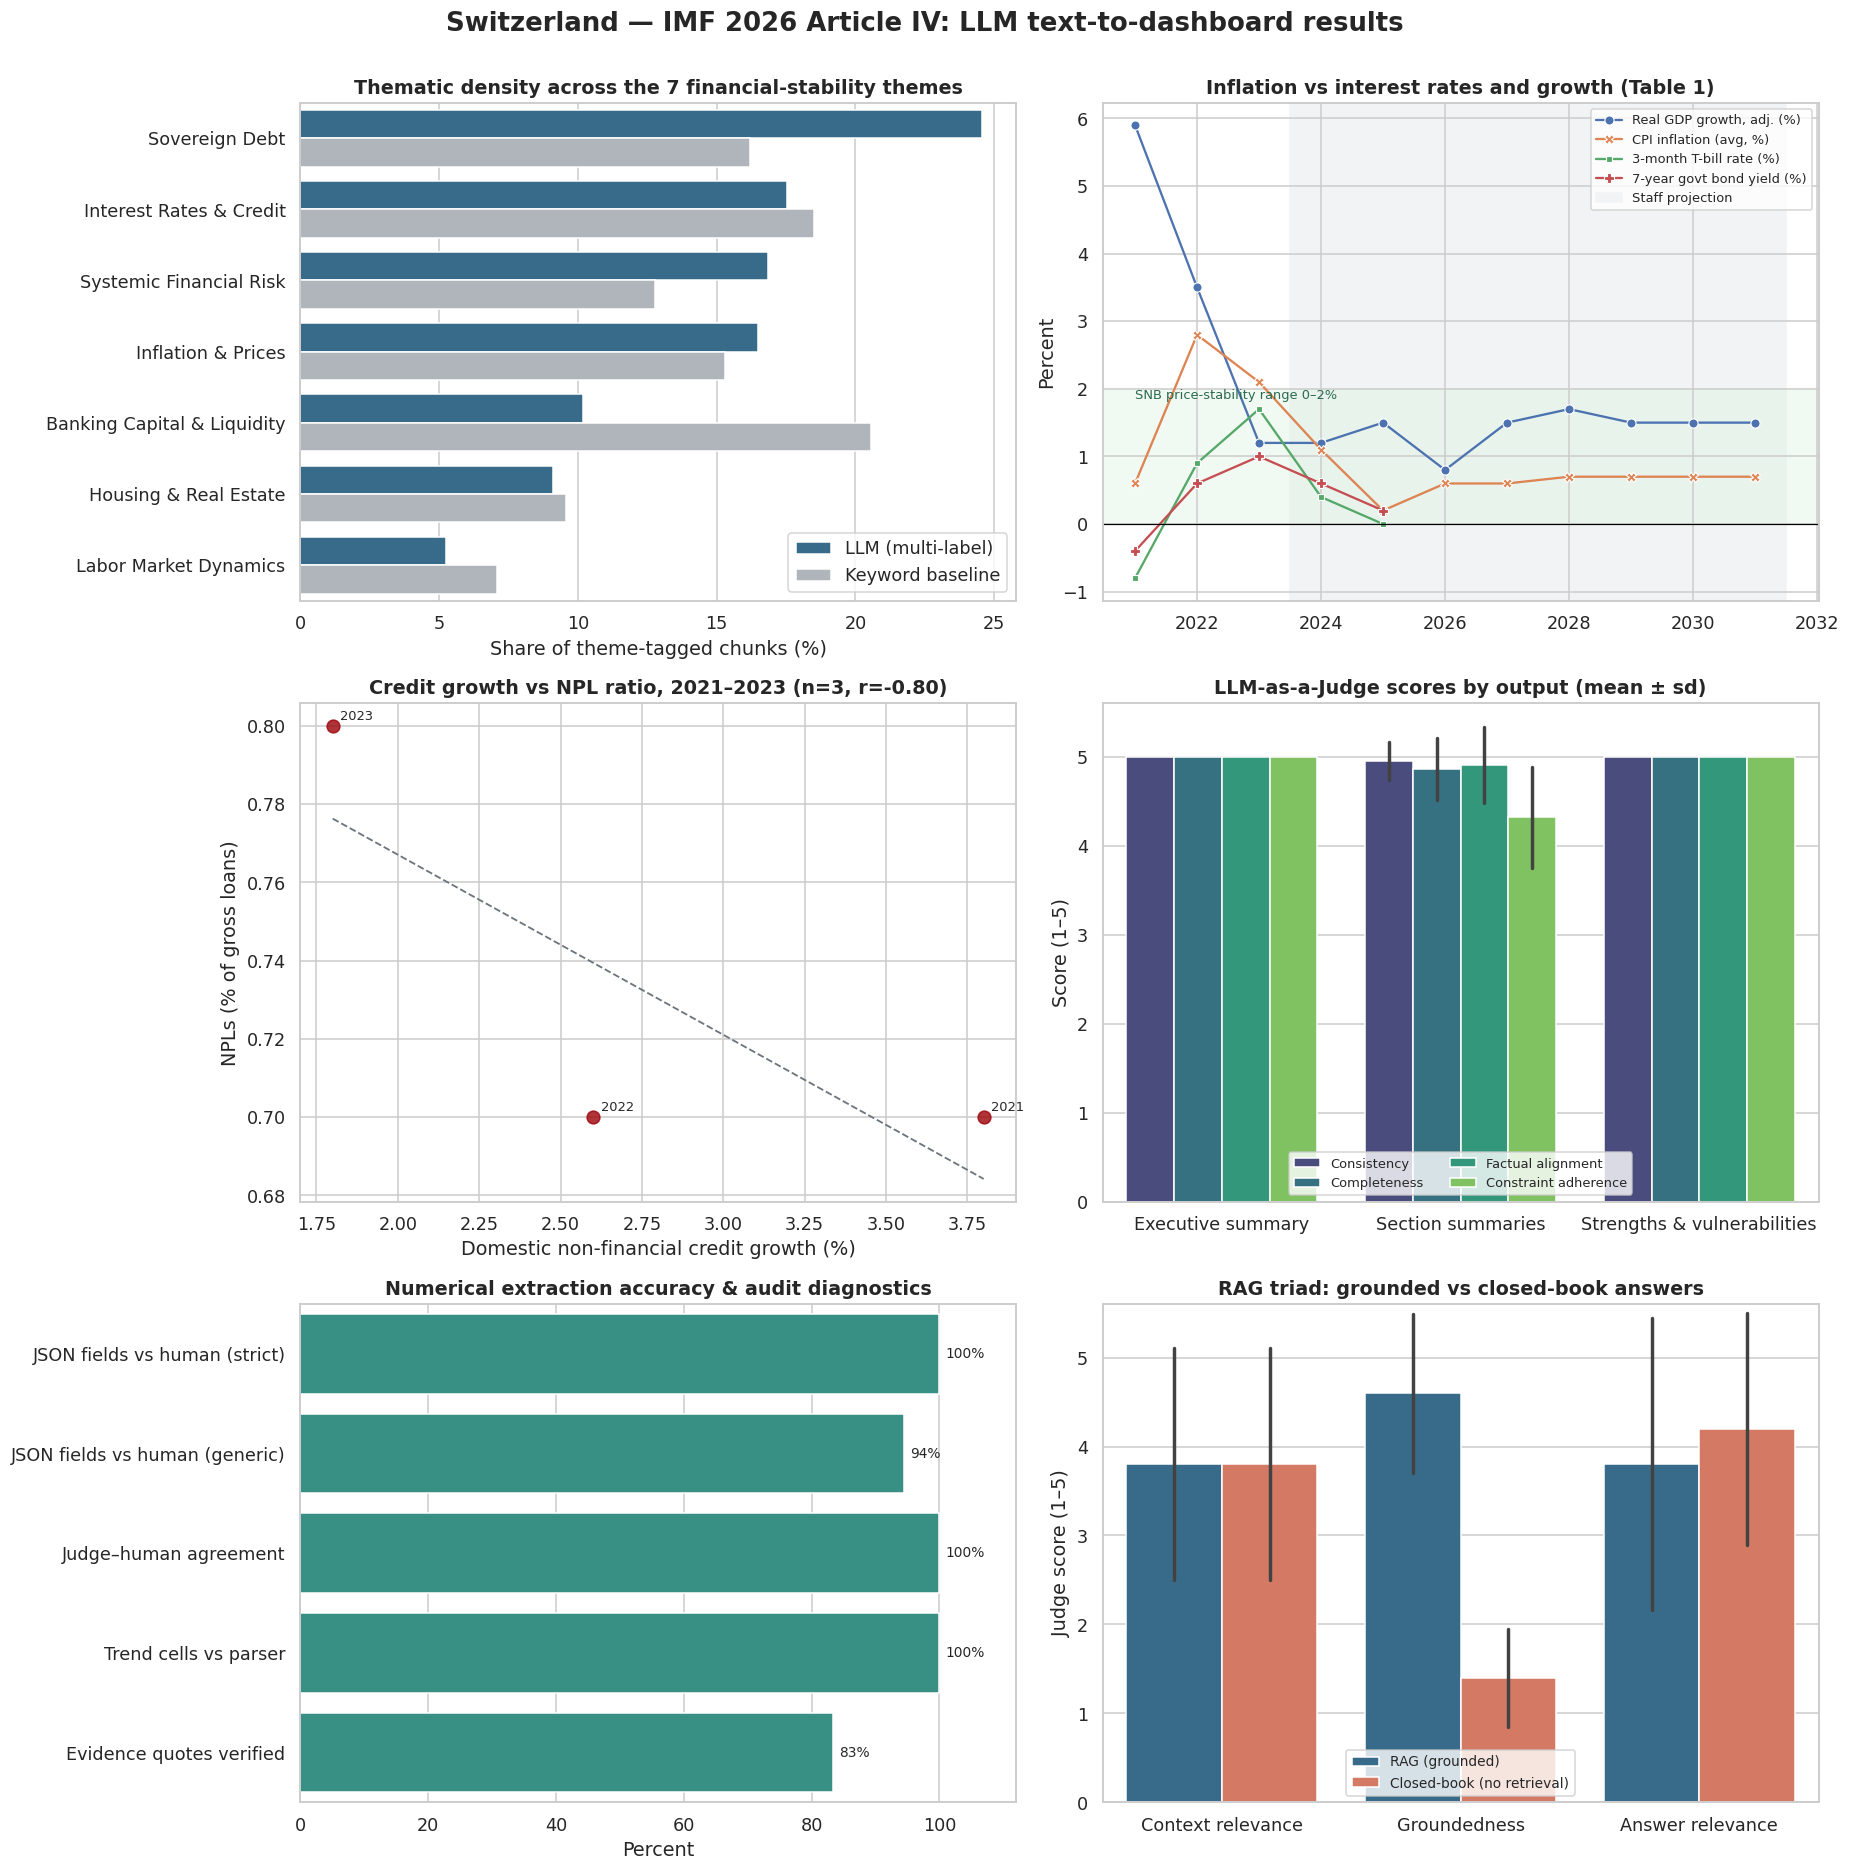

Saved: ['dashboard.png', 'fig1_thematic_density.png', 'fig2_inflation_vs_rates.png', 'fig3_credit_vs_npl.png', 'fig4_judge_scores.png', 'fig5_extraction_accuracy.png', 'fig6_rag_triad.png']


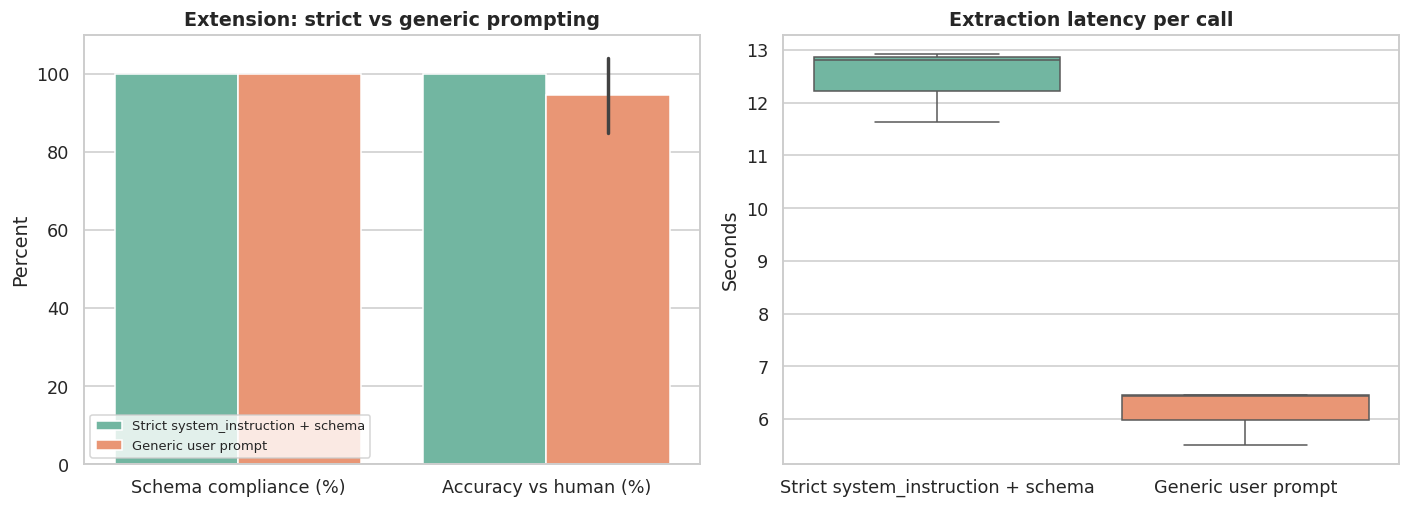

In [17]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.titleweight": "bold", "axes.titlesize": 12.5})
PALETTE = {"LLM (multi-label)": "#2a6f97", "Keyword baseline": "#adb5bd"}

# --- long-format tables ---
THEME_LONG = pd.melt(THEME_DF.rename(columns={"llm_share_pct": "LLM (multi-label)", "keyword_share_pct": "Keyword baseline"}),
                     id_vars="theme", value_vars=["LLM (multi-label)", "Keyword baseline"],
                     var_name="method", value_name="share_pct")
TRENDS_LONG = pd.melt(TRENDS_WIDE.reset_index(names="series"), id_vars="series", var_name="year", value_name="value")
TRENDS_LONG["year"] = TRENDS_LONG["year"].astype(int)
TRENDS_LONG["period"] = np.where(TRENDS_LONG["year"] >= PROJ_START, "Projection", "Actual")

judge_records = [{"output": "Executive summary", **jscores(EXEC_JUDGE)}]
judge_records += [{"output": "Section summaries", **jscores(r["judge"])} for r in SECTION_RESULTS if r["judge"]]
judge_records.append({"output": "Strengths & vulnerabilities", **jscores(RISK_JUDGE)})
JUDGE_LONG = pd.melt(pd.DataFrame(judge_records), id_vars="output", var_name="criterion", value_name="score")
JUDGE_LONG["criterion"] = JUDGE_LONG["criterion"].str.replace("_", " ").str.capitalize()

acc_rows = [{"metric": "JSON fields vs human (strict)", "value": 100 * JSON_REVIEW_DF["correct_vs_human"].mean()},
            {"metric": "Judge–human agreement", "value": 100 * JSON_REVIEW_DF["judge_agrees_with_human"].mean()},
            {"metric": "Trend cells vs parser", "value": 100 * trend_acc},
            {"metric": "Evidence quotes verified", "value": 100 * np.mean([r["quote_verified"] for r in JSON_REVIEW])}]
if len(EXT_DF):
    acc_rows.insert(1, {"metric": "JSON fields vs human (generic)", "value": 100 * EXT_DF.loc[EXT_DF.variant == "Generic user prompt", "accuracy"].mean()})
ACC_LONG = pd.melt(pd.DataFrame(acc_rows), id_vars="metric", value_vars="value", value_name="percent")
TRIAD_LONG = pd.melt(TRIAD_DF, id_vars=["id", "system"], var_name="criterion", value_name="score")
TRIAD_LONG["criterion"] = TRIAD_LONG["criterion"].str.replace("_", " ").str.capitalize()


# --- plotting functions (each draws on a given Axes) ---
def plot_themes(ax):
    order = THEME_DF.sort_values("llm_share_pct", ascending=False)["theme"]
    sns.barplot(data=THEME_LONG, y="theme", x="share_pct", hue="method", order=order, palette=PALETTE, ax=ax)
    ax.set(title="Thematic density across the 7 financial-stability themes", xlabel="Share of theme-tagged chunks (%)", ylabel="")
    ax.legend(title="", loc="lower right")


def plot_trends(ax):
    keep = TREND_PLOT_SERIES
    d = TRENDS_LONG[TRENDS_LONG["series"].isin(keep)].dropna(subset=["value"]).copy()
    d["series"] = d["series"].map(keep)
    sns.lineplot(data=d, x="year", y="value", hue="series", style="series", markers=True, dashes=False, ax=ax)
    ax.axvspan(PROJ_START - 0.5, d["year"].max() + 0.5, color="#f1f3f5", zorder=0, label="Staff projection")
    ax.axhline(0, color="black", lw=0.8)
    ax.axhspan(0, 2, color="#d8f3dc", alpha=0.35, zorder=0)
    ax.text(d["year"].min(), 1.85, "SNB price-stability range 0–2%", fontsize=8.5, color="#2d6a4f")
    ax.set(title="Inflation vs interest rates and growth (Table 1)", xlabel="", ylabel="Percent")
    ax.legend(title="", fontsize=8.5, loc="upper right")


def plot_credit_npl(ax):
    t1 = TRENDS_WIDE.loc[CREDIT_SERIES] if CREDIT_SERIES in TRENDS_WIDE.index else None
    t6 = TRENDS_WIDE.loc[NPL_SERIES] if NPL_SERIES in TRENDS_WIDE.index else None
    if t1 is None or t6 is None:
        ax.text(0.5, 0.5, "Series not available", ha="center"); return
    years = [y for y in t1.index if y in t6.index and pd.notna(t1[y]) and pd.notna(t6[y]) and y < PROJ_START]
    d = pd.DataFrame({"year": years, "credit_growth": [t1[y] for y in years], "npl": [t6[y] for y in years]})
    sns.regplot(data=d, x="credit_growth", y="npl", ax=ax, scatter_kws={"s": 70, "color": "#9d0208"},
                line_kws={"color": "#6c757d", "lw": 1.2, "ls": "--"}, ci=None)
    for (x, y), g in d.groupby(["credit_growth", "npl"]):          # merge labels of identical points
        ax.annotate(", ".join(str(int(v)) for v in sorted(g["year"])), (x, y), xytext=(5, 4),
                    textcoords="offset points", fontsize=8.5)
    rr = d[["credit_growth", "npl"]].corr().iloc[0, 1]
    ax.set(title=f"Credit growth vs NPL ratio, {years[0]}–{years[-1]} (n={len(d)}, r={rr:.2f})",
           xlabel="Domestic non-financial credit growth (%)", ylabel="NPLs (% of gross loans)")


def plot_judge(ax):
    sns.barplot(data=JUDGE_LONG, x="output", y="score", hue="criterion", errorbar="sd", palette="viridis", ax=ax)
    ax.set(title="LLM-as-a-Judge scores by output (mean ± sd)", xlabel="", ylabel="Score (1–5)", ylim=(0, 5.6))
    ax.legend(title="", fontsize=8.5, ncol=2, loc="lower center")


def plot_accuracy(ax):
    sns.barplot(data=ACC_LONG, y="metric", x="percent", color="#2a9d8f", ax=ax)
    for p in ax.patches:
        ax.annotate(f"{p.get_width():.0f}%", (p.get_width(), p.get_y() + p.get_height() / 2), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=9)
    ax.set(title="Numerical extraction accuracy & audit diagnostics", xlabel="Percent", ylabel="", xlim=(0, 112))


def plot_triad(ax):
    sns.barplot(data=TRIAD_LONG, x="criterion", y="score", hue="system", errorbar="sd",
                palette={"RAG (grounded)": "#2a6f97", "Closed-book (no retrieval)": "#e76f51"}, ax=ax)
    ax.set(title="RAG triad: grounded vs closed-book answers", xlabel="", ylabel="Judge score (1–5)", ylim=(0, 5.6))
    ax.legend(title="", fontsize=9, loc="lower center")


PANELS = [("fig1_thematic_density", plot_themes), ("fig2_inflation_vs_rates", plot_trends),
          ("fig3_credit_vs_npl", plot_credit_npl), ("fig4_judge_scores", plot_judge),
          ("fig5_extraction_accuracy", plot_accuracy), ("fig6_rag_triad", plot_triad)]

for name, fn in PANELS:                                  # individual high-resolution figures
    fig, ax = plt.subplots(figsize=(8, 5))
    fn(ax)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

fig, axes = plt.subplots(3, 2, figsize=(17, 17))
for (name, fn), ax in zip(PANELS, axes.ravel()):
    fn(ax)
fig.suptitle(f"{COUNTRY} — IMF {REPORT_YEAR} Article IV: LLM text-to-dashboard results", fontsize=17, fontweight="bold", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", sorted(p.name for p in FIG_DIR.glob("*.png")))

if len(EXT_DF):                                          # extension figure
    ext_long = pd.melt(EXT_DF.assign(schema_valid=EXT_DF["schema_valid"].astype(float) * 100, accuracy=EXT_DF["accuracy"] * 100),
                       id_vars=["variant", "run"], value_vars=["schema_valid", "accuracy"], var_name="metric", value_name="percent")
    ext_long["metric"] = ext_long["metric"].map({"schema_valid": "Schema compliance (%)", "accuracy": "Accuracy vs human (%)"})
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
    sns.barplot(data=ext_long, x="metric", y="percent", hue="variant", errorbar="sd", ax=axs[0], palette="Set2")
    axs[0].set(title="Extension: strict vs generic prompting", xlabel="", ylabel="Percent", ylim=(0, 110))
    axs[0].legend(title="", fontsize=8.5)
    sns.boxplot(data=EXT_DF, x="variant", y="latency_s", hue="variant", palette="Set2", ax=axs[1], legend=False)
    axs[1].set(title="Extraction latency per call", xlabel="", ylabel="Seconds")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig7_extension_strict_vs_generic.png", dpi=300, bbox_inches="tight")
    plt.show()

## 13. Run summary and output manifest

In [18]:
calls = pd.DataFrame(CALL_LOG)
print(f"LLM calls this run: {len(calls)} (from cache: {int(calls['from_cache'].sum()) if len(calls) else 0}); "
      f"generator={GEN_MODEL}, judge={JUDGE_MODEL}, temperature={TEMPERATURE}")
summary = {
    "report": REPORT_LABEL, "mode": MODE, "models": {"generator": GEN_MODEL, "judge": JUDGE_MODEL},
    "chunks": CHUNK_STATS, "section_summaries_all_under_100_words": bool((sec_df["words"] < 100).all()),
    "mean_judge_scores": JUDGE_LONG.groupby(["output", "criterion"])["score"].mean().round(2).unstack().to_dict(),
    "json_accuracy_vs_human": float(JSON_REVIEW_DF["correct_vs_human"].mean()),
    "judge_human_agreement": float(JSON_REVIEW_DF["judge_agrees_with_human"].mean()),
    "fallbacks": FALLBACK_LOG, "trend_cell_agreement": float(trend_acc),
    "rag_mean_triad": TRIAD_DF.groupby("system")[["context_relevance", "groundedness", "answer_relevance"]].mean().round(2).to_dict("index"),
    "abstention_correct_rate": float(np.mean([r["abstention_correct"] for r in RAG_RESULTS])),
}
save_json(summary, "run_summary.json")
print(json.dumps(summary, indent=2, default=str))
print("\nOutput files:", sorted(p.name for p in OUT_DIR.glob("*.json")))

LLM calls this run: 104 (from cache: 2); generator=gemini-3.5-flash, judge=gemini-3.8-flash, temperature=0.0
{
  "report": "IMF Country Report No. 26/233 \u2014 Switzerland 2026 Article IV",
  "mode": "live",
  "models": {
    "generator": "gemini-3.5-flash",
    "judge": "gemini-3.8-flash"
  },
  "chunks": {
    "n_units": 1291,
    "n_chunks": 204,
    "tokens_min": 53,
    "tokens_mean": 300.4,
    "tokens_max": 350,
    "chunk_tokens_target": 350,
    "overlap_tokens_target": 50
  },
  "section_summaries_all_under_100_words": true,
  "mean_judge_scores": {
    "Completeness": {
      "Executive summary": 5.0,
      "Section summaries": 4.86,
      "Strengths & vulnerabilities": 5.0
    },
    "Consistency": {
      "Executive summary": 5.0,
      "Section summaries": 4.95,
      "Strengths & vulnerabilities": 5.0
    },
    "Constraint adherence": {
      "Executive summary": 5.0,
      "Section summaries": 4.32,
      "Strengths & vulnerabilities": 5.0
    },
    "Factual alignmen